# World or a multifactor blend? And should JPGL replace some bonds?

**Starting point.** `portfolio_choice.ipynb` §7 settled the risk level and the portfolio: a **30% bad-case
drawdown** (the account falls 30% below its high, relative to what was paid in, in one path in twenty),
reached with **MSCI World 50% + euro government 7-10 50%**. Same investor: Italian tax resident, €1,000 up
front then €100 a month on Trade Republic savings plans, about 10 years, 26% tax on equity gains and 12.5%
on white-list government bonds, 0.2% stamp duty.

**The questions.**

| § | Question | How it is answered |
|---|---|---|
| 1–2 | What the four factor sleeves, JPGL and the S&P 500 are, and how they behaved | History 1999–2026 after fund cost; backtest vs live |
| 3 | What each can be expected to earn | The three return scenarios of `portfolio_choice`, plus a **Monte Carlo with uncertain expected returns** |
| 4 | **World vs a multifactor blend** (momentum, quality, value, min vol, 25% each) **vs the S&P 500**, same risk | Each dialled to a 30% bad-case drawdown, then compared on outcome |
| 5 | **Should part of the bond sleeve go into JPGL** (IE00BJRCLL96)? | Done naively (risk rises) and at constant risk |
| 6 | The answers | |
| 7 | One fund instead of four? A better factor mix? Sector and region diversification | Single-fund multifactor ETFs, every mix at the risk level, holdings and crisis tests |
| 8 | Is euro govt 7-10 the right bond sleeve? | Every maturity, hedged Treasuries and cash at the same risk; real funds; rate paths inside the plan; a fund vs held bonds, distributing vs accumulating, and a maturity glide path, on simulated yield curves |

All series are monthly, in **EUR**, total return. Not financial advice.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import optimize

import design as D
import etfs as ETF
import pfutils as pf

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
END = pd.Timestamp("2026-09-30")  # last complete month in this run

INK, INK2, MUTED, GRID, BASE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SLOT = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": BASE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2,
    "ytick.labelcolor": INK2, "lines.linewidth": 2, "legend.frameon": False, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})
pct0 = mtick.PercentFormatter(1.0, decimals=0)
pct1 = mtick.PercentFormatter(1.0, decimals=1)
eur_k = mtick.FuncFormatter(lambda v, _: f"€{v/1000:.1f}k")
P1 = lambda cols: {c: "{:.1%}" for c in cols}
EUR0 = lambda cols: {c: "€{:,.0f}" for c in cols}

eur1m = pf.ecb_series("FM/M.U2.EUR.RT.MM.EURIBOR1MD_.HSTA") / 100
eur1m.index = eur1m.index + pd.offsets.MonthEnd(0)
RF = eur1m / 12  # monthly EUR risk-free (1-month Euribor)

eq = D.equity_indexes().loc[:END]
eq["S&P 500"] = D.other_indexes(END)["S&P 500"]   # S&P's own total return, put on MSCI's net-dividend footing
bonds, blong = D.bond_indexes(END)
FAC = ["World Momentum", "World Quality SN", "World Enhanced Value", "World Min Vol"]
FLAB = {"World Momentum": "Momentum", "World Quality SN": "Quality", "World Enhanced Value": "Value", "World Min Vol": "Min Vol"}
SP = "S&P 500"

## 1 · The funds and what they cost

The four factor sleeves are the MSCI World factor indexes that a UCITS ETF on Trade Republic actually
tracks: **Momentum**, **Quality** (the *Sector Neutral* variant — every "World Quality" ETF tracks it),
**Value** (the *Enhanced* variant, likewise) and **Minimum Volatility**. Each fund's gap to its index
is measured as in `portfolio_choice` §1, but a single fund's measurement is too noisy to tell it apart from
another's. So each sleeve is charged **its TER less one common offset** — the securities lending and
withholding-tax treaty rate that an Irish or Luxembourg UCITS gets and MSCI's *net* index does not assume —
estimated from all the funds together.

**JPGL** tracks J.P. Morgan's own *Diversified Factor Global Developed (Region Aware)* index, which is not
public, so its gap cannot be measured; it gets the same TER-less-offset treatment (TER 0.19%). It has its own
fund history only from 2019-07.

**The S&P 500** is the other single-fund alternative to World: the 500 largest US companies, about 70% of
World already, so it is World without the other 30% (Europe, Japan, the rest) rather than a factor tilt. Its
index history is S&P's total return with 70% of dividends kept, the same net-dividend footing as MSCI's
indexes; its funds are the cheapest equity ETFs on the market (TER 0.03–0.07%).

In [2]:
def measure(recs):
    rows = []
    for f in recs:
        try:
            r = D.etf_returns(f["ticker"], END, f["start"])
        except Exception:
            r = None
        est = D.drag_slope(r, eq[f["index"]]) if r is not None else None
        rows.append({"Index": f["index"], "ETF": f["name"], "Ticker": f["ticker"], "ISIN": f["isin"], "TER": f["ter"],
                     "Measured cost /yr": est["Drag"] if est else np.nan, "± (1 s.e.)": est["SE"] if est else np.nan,
                     "Months": est["Months"] if est else 0, "TR plan": f["tr_plan"], "Repl.": f["repl"], "Acc.": f["acc"]})
    return pd.DataFrame(rows)

def best_cost(tab):
    # one fund per index: savings-plan physical funds first, then the lowest TER, then the longest record
    ok = tab[tab["Acc."]].copy()
    ok["Tier"] = np.where(ok["Repl."] != "Physical", 2, np.where(ok["TR plan"] == "Y", 0, 1))
    ok = ok.sort_values(["Tier", "TER", "Months"], ascending=[True, True, False])
    return ok.groupby("Index").head(1).set_index("Index")

EQS = ["World"] + FAC + [SP]
BEST = best_cost(measure([f for f in ETF.records(ETF.EQUITY) if f["index"] in EQS])).loc[EQS]
# One fund's measured cost is too noisy to use on its own. Pooled, the measurements pin down the common
# offset of an Irish/Lux UCITS against MSCI's net index (securities lending + treaty withholding tax):
# every sleeve is charged TER − offset, the offset precision-weighted across the funds with 3+ years.
m_ = BEST[BEST["Months"] >= 36]
wt = 1 / m_["± (1 s.e.)"] ** 2
OFFSET = float(((m_["TER"] - m_["Measured cost /yr"]) * wt).sum() / wt.sum())
OFFSET_SE = float(1 / np.sqrt(wt.sum()))
JPGL_TER = 0.0019
BEST.loc["JPGL"] = {"ETF": "JPMorgan Global Equity Multi-Factor UCITS ETF USD (acc)", "Ticker": "JPGL.DE",
                    "ISIN": "IE00BJRCLL96", "TER": JPGL_TER, "Months": 0, "TR plan": "Y*"}
BEST["Cost used"] = BEST["TER"] - OFFSET
display(BEST[["ETF", "Ticker", "ISIN", "TER", "Measured cost /yr", "± (1 s.e.)", "Months", "Cost used", "TR plan"]]
        .style.format({"TER": "{:.2%}", "Measured cost /yr": "{:+.2%}", "± (1 s.e.)": "{:.2%}", "Cost used": "{:+.2%}"}, na_rep="—"))
print("Measured cost = trend of the fund's gap to its index; ± = its autocorrelation-robust standard error.")
print("No single measurement separates one fund from another, so every sleeve, JPGL included, is charged its TER less")
print(f"the common offset the measurements imply together: {OFFSET:.2%} ± {OFFSET_SE:.2%}. TR plan Y* = listed by justETF; confirm in the app.")

,ETF,Ticker,ISIN,TER,Measured cost /yr,± (1 s.e.),Months,Cost used,TR plan
Index,,,,,,,,,
World,UBS Core MSCI World,UETW.DE,IE00BD4TXV59,0.06%,+0.01%,0.39%,76,-0.13%,Y
World Momentum,Xtrackers MSCI World Momentum 1C,XDEM.DE,IE00BL25JP72,0.25%,+0.08%,0.51%,141,+0.06%,Y
World Quality SN,iShares Edge MSCI World Quality Factor,IS3Q.DE,IE00BP3QZ601,0.25%,+0.12%,0.23%,140,+0.06%,Y
World Enhanced Value,iShares Edge MSCI World Value Factor,IS3S.DE,IE00BP3QZB59,0.25%,-0.01%,0.18%,140,+0.06%,Y
World Min Vol,Xtrackers MSCI World Minimum Volatility 1C,XDEB.DE,IE00BL25JN58,0.25%,+0.05%,0.43%,141,+0.06%,Y
S&P 500,SPDR S&P 500 Acc,SPYL.DE,IE000XZSV718,0.03%,+0.07%,0.84%,28,-0.16%,Y
JPGL,JPMorgan Global Equity Multi-Factor UCITS ETF USD (acc),JPGL.DE,IE00BJRCLL96,0.19%,—,—,0,-0.00%,Y*


Measured cost = trend of the fund's gap to its index; ± = its autocorrelation-robust standard error.
No single measurement separates one fund from another, so every sleeve, JPGL included, is charged its TER less
the common offset the measurements imply together: 0.19% ± 0.12%. TR plan Y* = listed by justETF; confirm in the app.


**JPGL before 2019.** Its own history is seven years, which contains one bear market (2022) and no deep
one. To simulate it on the same 1999–2026 sample as everything else, the years before its launch are filled
with **the mix of MSCI indexes that best reproduces its live returns** (weights ≥ 0, summing to one, fitted
on its fund returns gross of the TER). This keeps its defensive shape in the GFC and the dot-com bust, which
its own short record cannot show. It is an approximation, and labelled as one wherever it is used.

In [3]:
jp = D.etf_returns("JPGL.DE", END)
jg = jp + JPGL_TER / 12                                     # gross of the fee, comparable with index returns
STY = ["World"] + FAC
x = pd.concat([jg.rename("JPGL"), eq[STY]], axis=1).dropna()
A, y = x[STY].to_numpy(), x["JPGL"].to_numpy()
w_sty = optimize.minimize(lambda w: ((y - A @ w) ** 2).sum(), np.full(len(STY), 1 / len(STY)),
                          bounds=[(0, 1)] * len(STY), constraints=({"type": "eq", "fun": lambda w: w.sum() - 1},)).x
fit = A @ w_sty
STYLE = pd.Series(w_sty, index=[("World" if s == "World" else FLAB[s]) for s in STY])
print(f"JPGL live {jp.index[0]:%Y-%m} → {jp.index[-1]:%Y-%m} ({len(jp)} months). Best-fitting mix of MSCI indexes:")
display(STYLE.to_frame("Weight").T.style.format("{:.0%}"))
print(f"Correlation with the mix {np.corrcoef(y, fit)[0, 1]:.3f}; tracking error {(y - fit).std() * np.sqrt(12):.1%}/yr; "
      f"JPGL beat the mix by {(y - fit).mean() * 12:+.1%}/yr over its live years.")
print("Fitted mix: " + ", ".join(f"{k} {v:.0%}" for k, v in STYLE.sort_values(ascending=False).items() if v >= 0.05) + ".")

JPGL live 2019-11 → 2026-09 (83 months). Best-fitting mix of MSCI indexes:


,World,Momentum,Quality,Value,Min Vol
Weight,30%,0%,3%,20%,46%


Correlation with the mix 0.955; tracking error 4.0%/yr; JPGL beat the mix by +0.6%/yr over its live years.
Fitted mix: Min Vol 46%, World 30%, Value 20%.


## 2 · History: World, the four factors, the blend and JPGL

**The multifactor blend** holds the four factor sleeves at 25% each. In history it is rebalanced monthly
(a clean benchmark); in the simulation of the actual plan it is four savings plans of €12.50 each with no
selling, so the weights drift.

Window 1999-02 → 2026-09, after fund cost. MSCI World's EUR series starts in 2001, so its first 23 months
are MSCI ACWI IMI (monthly correlation 0.99). **The market** for beta and alpha is **MSCI World** (index
level), the universe the four factor indexes are drawn from. Against a broader market such as ACWI IMI, World
itself shows about +0.5%/yr of "alpha" since 2014 (it holds no emerging markets or small caps); measuring the
factors against ACWI IMI would credit them with that while World, the alternative, is held at zero.

In [4]:
NET = {k: D.net_of_cost(eq[k], BEST.loc[k, "Cost used"]) for k in EQS}
ACWI = eq["ACWI IMI"]
H_ = pd.DataFrame(NET).loc["1999-02":END]
H_["World"] = pf.splice(H_["World"].dropna(), ACWI.loc["1999-02":])
gross = pd.DataFrame({k: eq[k] for k in STY}).loc["1999-02":END]
gross["World"] = pf.splice(gross["World"].dropna(), ACWI.loc["1999-02":])
MKT = gross["World"]                                   # the market for beta and alpha: MSCI World, index level
H_["JPGL"] = pf.splice(jp, gross[STY] @ w_sty - JPGL_TER / 12)
H_["Multifactor (4 × 25%)"] = H_[FAC].mean(axis=1)
BD = pf.splice(bonds["EUR Govt 7-10"].dropna(), blong["Bund 7-10"])
H_["EUR Govt 7-10"] = D.net_of_cost(BD, 0.0015)
H_ = H_.dropna()
rfH = RF.reindex(H_.index).ffill()

def hist_row(s):
    st, ab = pf.perf_stats(s), D.alpha_beta(s, MKT, RF)
    ct = D.crisis_table(s.to_frame("x"))["x"]
    return {"CAGR": st["CAGR"], "Volatility": st["Volatility"], "Max drawdown": st["Max drawdown"],
            "Longest underwater (m)": st["Longest underwater (m)"], "Beta": ab["Beta"], "Alpha /yr": ab["Alpha /yr"],
            "Alpha t-stat": ab["Alpha t-stat"], "Dot-com": ct["Dot-com 2000-03"], "GFC": ct["GFC 2007-09"],
            "COVID": ct["COVID 2020"], "2022": ct["Inflation 2022"]}

ORDER = ["World", SP] + FAC + ["Multifactor (4 × 25%)", "JPGL", "EUR Govt 7-10"]
HT = pd.DataFrame({k: hist_row(H_[k]) for k in ORDER}).T.rename(index=FLAB | {"JPGL": "JPGL (proxy before 2019-11)"})
HT.loc["World", "Alpha t-stat"] = np.nan          # World against itself: its "alpha" is only its fund cost, no test
display(HT.style.format(P1(["CAGR", "Volatility", "Max drawdown", "Alpha /yr", "Dot-com", "GFC", "COVID", "2022"])
                        | {"Longest underwater (m)": "{:.0f}", "Beta": "{:.2f}", "Alpha t-stat": "{:+.1f}"}, na_rep="—")
        .background_gradient(cmap="RdYlGn", subset=["Dot-com", "GFC", "COVID", "2022"], vmin=-0.5, vmax=0.2))
print("Correlations, 1999–2026:")
display(H_[ORDER].rename(columns=FLAB).corr().style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1))

,CAGR,Volatility,Max drawdown,Longest underwater (m),Beta,Alpha /yr,Alpha t-stat,Dot-com,GFC,COVID,2022
World,7.4%,14.2%,-56.5%,161,1.00,0.1%,—,-53.8%,-47.5%,-19.8%,-13.3%
S&P 500,8.2%,15.2%,-61.5%,164,1.03,0.8%,+1.0,-48.6%,-44.4%,-18.9%,-11.8%
Momentum,9.5%,15.2%,-55.9%,147,0.92,2.8%,+2.1,-55.9%,-46.3%,-15.8%,-15.6%
Quality,7.8%,13.7%,-48.3%,140,0.93,0.9%,+1.3,-43.2%,-43.9%,-17.8%,-15.8%
Value,10.0%,15.6%,-54.3%,75,0.98,2.8%,+1.6,-32.2%,-52.5%,-23.4%,-10.0%
Min Vol,6.5%,10.8%,-39.5%,73,0.63,1.3%,+1.0,-30.7%,-35.7%,-16.4%,-4.8%
Multifactor (4 × 25%),8.6%,12.6%,-45.4%,64,0.86,2.0%,+3.2,-41.0%,-44.7%,-18.4%,-11.5%
JPGL (proxy before 2019-11),7.6%,12.4%,-45.7%,71,0.83,1.2%,+1.4,-39.4%,-43.4%,-21.7%,-7.2%
EUR Govt 7-10,3.4%,5.2%,-22.9%,69,0.01,1.8%,+1.5,26.9%,9.6%,-3.0%,-17.8%


Correlations, 1999–2026:


,World,S&P 500,Momentum,Quality,Value,Min Vol,Multifactor (4 × 25%),JPGL,EUR Govt 7-10
World,1.00,0.96,0.85,0.97,0.90,0.82,0.97,0.95,0.02
S&P 500,0.96,1.00,0.82,0.96,0.83,0.84,0.94,0.93,0.01
Momentum,0.85,0.82,1.00,0.83,0.74,0.71,0.90,0.80,-0.00
Quality,0.97,0.96,0.83,1.00,0.85,0.85,0.96,0.94,0.04
Value,0.90,0.83,0.74,0.85,1.00,0.72,0.91,0.90,-0.01
Min Vol,0.82,0.84,0.71,0.85,0.72,1.00,0.88,0.92,0.13
Multifactor (4 × 25%),0.97,0.94,0.90,0.96,0.91,0.88,1.00,0.97,0.04
JPGL,0.95,0.93,0.80,0.94,0.90,0.92,0.97,1.00,0.05
EUR Govt 7-10,0.02,0.01,-0.00,0.04,-0.01,0.13,0.04,0.05,1.00


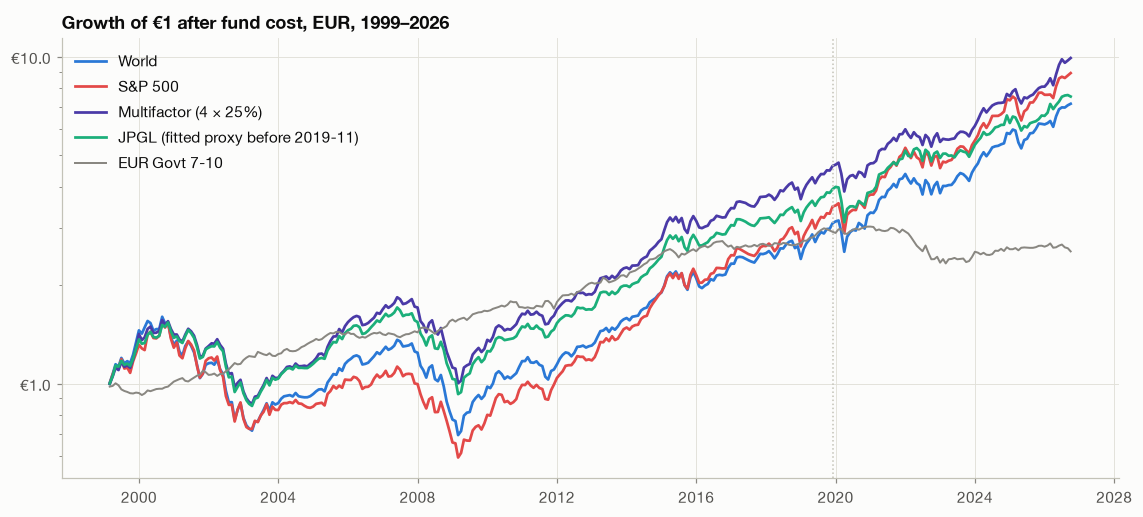

In [5]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for k, c in [("World", SLOT[0]), (SP, SLOT[5]), ("Multifactor (4 × 25%)", SLOT[4]), ("JPGL", SLOT[1]), ("EUR Govt 7-10", MUTED)]:
    ax.plot(pf.wealth(H_[k]), color=c, lw=1.8 if k != "EUR Govt 7-10" else 1.3,
            label=k if k != "JPGL" else "JPGL (fitted proxy before 2019-11)")
ax.axvline(jp.index[0], color=BASE, lw=1, ls=":")
ax.set_yscale("log"); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"€{v:.1f}"))
ax.set_title("Growth of €1 after fund cost, EUR, 1999–2026")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Backtest versus live.** MSCI computes each factor index back to 1999, but each was *launched* later and
the years before launch were designed knowing what had worked. Only the live years are evidence. The blend
is live from 2014-12, when the last of its four indexes launched. Index level, before fund cost, against
MSCI World; t-stats are Newey-West (robust to autocorrelation).

In [6]:
LAUNCH = {"World Min Vol": "2008-06", "World Quality SN": "2014-12", "World Momentum": "2013-12",
          "World Enhanced Value": "2014-08"}
MF_RAW = eq[FAC].mean(axis=1)
SER = {**{k: (eq[k], l) for k, l in LAUNCH.items()}, "Multifactor (4 × 25%)": (MF_RAW, "2014-12"), "JPGL": (jg, None)}
rows = []
for k, (s, l) in SER.items():
    for lab, sl in ({"Backtest": slice("1999-01", l), "Live": slice(l, END)} if l else {"Live": slice(None, END)}).items():
        x_ = s.loc[sl].dropna()
        ab = D.alpha_beta(x_, MKT, RF)
        rows.append({"Sleeve": FLAB.get(k, k), "Period": lab, "From": f"{x_.index[0]:%Y-%m}", "Months": len(x_),
                     "Beta": ab["Beta"], "Alpha /yr": ab["Alpha /yr"], "Alpha t-stat": ab["Alpha t-stat"]})
BL = pd.DataFrame(rows)
display(BL.style.format({"Beta": "{:.2f}", "Alpha /yr": "{:+.1%}", "Alpha t-stat": "{:+.1f}"}).hide(axis="index"))
hit = BL.loc[(BL["Period"] == "Live") & (BL["Alpha t-stat"].abs() >= 2), "Sleeve"].tolist()
print("Alpha = return beyond what the sleeve's beta to MSCI World explains. |t| above ~2 would be evidence; "
      + (f"live, only {', '.join(hit)} reach it." if hit else "none reaches it live."))

Sleeve,Period,From,Months,Beta,Alpha /yr,Alpha t-stat
Min Vol,Backtest,1999-01,114,0.64,+0.4%,+0.2
Min Vol,Live,2008-06,220,0.62,+1.9%,+1.1
Quality,Backtest,1999-01,192,0.91,+1.1%,+1.2
Quality,Live,2014-12,142,0.97,+0.4%,+0.5
Momentum,Backtest,1999-01,180,0.89,+2.3%,+1.1
Momentum,Live,2013-12,154,0.96,+3.1%,+1.9
Value,Backtest,1999-01,188,1.00,+5.4%,+2.6
Value,Live,2014-08,146,0.96,-0.2%,-0.1
Multifactor (4 × 25%),Backtest,1999-01,192,0.86,+2.7%,+3.4
Multifactor (4 × 25%),Live,2014-12,142,0.87,+1.1%,+1.4


Alpha = return beyond what the sleeve's beta to MSCI World explains. |t| above ~2 would be evidence; none reaches it live.


## 3 · What each sleeve can be expected to earn

### 3a · The three scenarios

The same three as `portfolio_choice` §4b, extended to quality, value and JPGL. All start from **6.3% for
global equity and 2.3% for euro cash** (J.P. Morgan 2026 long-term assumptions); each sleeve's fund cost is
then subtracted. Bonds earn today's yield less the fee in every scenario.

| Scenario | Rule | What it believes |
|---|---|---|
| **Same return** | Every equity sleeve earns 6.3% | Factor tilts change the ride, not the destination |
| **Live record** | Cash + (multiple of the market's excess return the sleeve earned after launch) × (6.3% − cash) | Factor premia persist as they did live |
| **Beta-priced** | Cash + beta × (6.3% − cash) | Lower-risk sleeves earn proportionally less (CAPM) |

### 3b · The Monte Carlo: uncertain expected returns

The three scenarios each assume one set of expected returns is *known*. The Monte Carlo instead treats the
expected returns themselves as uncertain and draws **a different set for every simulated path**:

- **Market**: 6.3% ± 1.5 points (one standard deviation) — the usual spread between houses' long-term assumptions.
- **Each equity sleeve**: cash + beta × (market − cash) + an **alpha**. The alpha is the sleeve's live alpha
  against MSCI World over the common live window from 2014-12 (JPGL: its own years), **shrunk towards zero by
  how noisy it is**: a prior that factor alphas are centred on zero with a spread of ±1.5%/yr (the range of
  long-only factor premia after costs and after publication — McLean & Pontiff 2016), combined with the live
  estimate and its standard error. A noisy record moves the centre little; a precise one moves it more. The
  spread is what remains uncertain after both. The alphas are drawn **jointly**, correlated as the sleeves'
  residual returns are, so a bad decade for one factor style tends to be shared. World's alpha is zero by
  construction: it is the market. **The S&P 500** gets the same treatment: its decade of US outperformance is
  a live record like any other, and it too is shrunk towards zero — the prior that a region, like a factor,
  carries no premium you can count on.
- **Bonds**: today's yield less the fee, ± 0.5 points (reinvestment rate, spreads of the higher-yielding issuers).

The month-to-month shapes — crises, volatility clusters, the stock–bond correlation — still come from the
same block bootstrap of 1999–2026. The scenarios ask "*if* this is true, what happens?"; the Monte Carlo
asks "given that we do not know which is true, what is the spread of outcomes?"

In [7]:
X = H_[["World", SP] + FAC + ["JPGL", "EUR Govt 7-10"]]
EQC = ["World", SP] + FAC + ["JPGL"]
H, N = 120, 5000
TAX = np.array([0.26 if c in EQC else 0.125 for c in X.columns])
EQ_CMA, RF_CMA = 0.063, 0.023
B_Y = D.current_yields(END).loc["7-10", "Euro govt"]
BOND_T = B_Y - 0.0015
BETA = {k: D.beta(X[k], MKT) for k in EQC}

cg = lambda x: (1 + x).prod() ** (12 / len(x)) - 1
LIVE0 = "2014-12"   # all four factor indexes live: one common window, so no sleeve's record holds a crisis the others' miss
SRC = {**{k: SER[k] for k in FAC + ["JPGL"]}, SP: (eq[SP], LIVE0)}   # the S&P 500 is real history throughout; same window
live_slice = lambda k: SRC[k][0].loc[(LIVE0 if SRC[k][1] else None):END].dropna()
LIVE, RESID = {}, {}
for k in [SP] + FAC + ["JPGL"]:
    x_ = live_slice(k)
    m_, f_ = MKT.reindex(x_.index), RF.reindex(x_.index).ffill()
    ab = D.alpha_beta(x_, MKT, RF)
    RESID[k] = (x_ - f_) - ab["Beta"] * (m_ - f_)
    LIVE[k] = {"Live since": f"{x_.index[0]:%Y-%m}", "Multiple of market excess return": (cg(x_) - cg(f_)) / (cg(m_) - cg(f_)),
               "Live alpha /yr": ab["Alpha /yr"], "Alpha s.e.": abs(ab["Alpha /yr"] / ab["Alpha t-stat"])}
LIVE = pd.DataFrame(LIVE).T
# the alpha estimates are correlated as the sleeves' residual returns are: drawn jointly in the Monte Carlo
ACORR = pd.DataFrame(RESID).corr()
ACHOL = np.linalg.cholesky(ACORR.to_numpy())

S_SAME, S_LIVE, S_BETA, S_MC = "Same return", "Live record", "Beta-priced", "Monte Carlo"
cost = BEST["Cost used"]
TGT = {S_SAME: {k: EQ_CMA - cost[k] for k in EQC},
       S_LIVE: {k: RF_CMA + (LIVE.loc[k, "Multiple of market excess return"] if k in LIVE.index else 1) * (EQ_CMA - RF_CMA) - cost[k] for k in EQC},
       S_BETA: {k: RF_CMA + BETA[k] * (EQ_CMA - RF_CMA) - cost[k] for k in EQC}}
for s in TGT:
    TGT[s]["EUR Govt 7-10"] = BOND_T

# Monte Carlo prior: centre and spread of each column's expected compound return
TAU = 0.015                                                    # prior spread of a factor alpha around zero
shrink = lambda k: TAU**2 / (TAU**2 + LIVE.loc[k, "Alpha s.e."] ** 2)
ALPHA0 = {k: shrink(k) * LIVE.loc[k, "Live alpha /yr"] if k in LIVE.index else 0.0 for k in EQC}
ASE = {k: np.sqrt(shrink(k)) * LIVE.loc[k, "Alpha s.e."] if k in LIVE.index else 0.0 for k in EQC}
LIVE["Shrunk alpha (Monte Carlo centre)"] = [ALPHA0[k] for k in LIVE.index]
LIVE["± after shrinkage"] = [ASE[k] for k in LIVE.index]
MC_SD_MKT, MC_SD_BOND = 0.015, 0.005
MC_MU = {**{k: RF_CMA + BETA[k] * (EQ_CMA - RF_CMA) + ALPHA0[k] - cost[k] for k in EQC}, "EUR Govt 7-10": BOND_T}

def mc_paths(seed=41):
    P = D.bootstrap_on_targets(X, H, N, 12, seed=seed, targets=MC_MU)
    rng = np.random.default_rng(seed + 1000)
    mkt = rng.normal(0, MC_SD_MKT, N)
    z = pd.DataFrame(rng.standard_normal((N, len(ACORR))) @ ACHOL.T, columns=ACORR.index)
    draws = {}
    for i, c in enumerate(X.columns):
        mu = MC_MU[c]
        d = BETA[c] * mkt + (ASE[c] * z[c].to_numpy() if c in z else 0.0) if c in EQC else rng.normal(0, MC_SD_BOND, N)
        draws[c] = mu + d
        shift = (np.log1p(mu + d) - np.log1p(mu)) / 12               # move each path's compound mean by d
        P[..., i] = (1 + P[..., i]) * np.exp(shift)[:, None] - 1
    return P, pd.DataFrame(draws)

PATHS = {s: D.bootstrap_on_targets(X, H, N, 12, seed=41, targets=t) for s, t in TGT.items()}
PATHS[S_MC], MC_DRAWS = mc_paths()

print(f"Live record of each sleeve against MSCI World from {LIVE0} (JPGL: its own years), index level, before cost:")
display(LIVE.style.format({"Multiple of market excess return": "{:.2f}×", "Live alpha /yr": "{:+.2%}", "Alpha s.e.": "{:.2%}",
                           "Shrunk alpha (Monte Carlo centre)": "{:+.2%}", "± after shrinkage": "{:.2%}"}))
print("Correlation of the alpha draws (the sleeves' residual returns over the same window):")
display(ACORR.rename(index=FLAB, columns=FLAB).style.format("{:+.2f}"))
ER = pd.DataFrame({**TGT, "Monte Carlo: centre": MC_MU,
                   "Monte Carlo: 5th–95th pct": {c: f"{np.percentile(MC_DRAWS[c], 5):.1%} to {np.percentile(MC_DRAWS[c], 95):.1%}" for c in X.columns}})
ER.index = [FLAB.get(i, i) for i in ER.index]
print("Expected compound return per year, after fund cost:")
display(ER.style.format("{:.2%}", subset=[c for c in ER.columns if "pct" not in c]))
mf_draw = MC_DRAWS[FAC].mean(axis=1) - MC_DRAWS["World"]
print(f"Monte Carlo: the multifactor blend's expected return minus World's is {mf_draw.median():+.2%} at the median, "
      f"{np.percentile(mf_draw, 5):+.2%} to {np.percentile(mf_draw, 95):+.2%} (5th–95th), positive on {(mf_draw > 0).mean():.0%} of paths.")

Live record of each sleeve against MSCI World from 2014-12 (JPGL: its own years), index level, before cost:


,Live since,Multiple of market excess return,Live alpha /yr,Alpha s.e.,Shrunk alpha (Monte Carlo centre),± after shrinkage
S&P 500,2014-12,1.19×,+1.39%,0.75%,+1.11%,0.67%
World Momentum,2014-12,1.25×,+3.23%,1.77%,+1.35%,1.14%
World Quality SN,2014-12,1.00×,+0.39%,0.83%,+0.30%,0.73%
World Enhanced Value,2014-12,0.94×,+0.04%,2.83%,+0.01%,1.33%
World Min Vol,2014-12,0.66×,+0.66%,1.87%,+0.26%,1.17%
JPGL,2019-11,0.76×,-0.67%,2.40%,-0.19%,1.27%


Correlation of the alpha draws (the sleeves' residual returns over the same window):


,S&P 500,Momentum,Quality,Value,Min Vol,JPGL
S&P 500,+1.00,+0.23,+0.11,-0.39,+0.14,-0.23
Momentum,+0.23,+1.00,+0.21,-0.15,+0.00,-0.21
Quality,+0.11,+0.21,+1.00,-0.33,+0.43,+0.15
Value,-0.39,-0.15,-0.33,+1.00,-0.16,+0.31
Min Vol,+0.14,+0.00,+0.43,-0.16,+1.00,+0.64
JPGL,-0.23,-0.21,+0.15,+0.31,+0.64,+1.00


Expected compound return per year, after fund cost:


,Same return,Live record,Beta-priced,Monte Carlo: centre,Monte Carlo: 5th–95th pct
World,6.43%,6.43%,6.43%,6.43%,3.9% to 8.9%
S&P 500,6.46%,7.21%,6.60%,7.71%,4.9% to 10.5%
Momentum,6.24%,7.24%,5.90%,7.26%,4.3% to 10.2%
Quality,6.24%,6.26%,5.98%,6.28%,3.5% to 8.9%
Value,6.24%,6.00%,6.18%,6.19%,2.9% to 9.4%
Min Vol,6.24%,4.89%,4.74%,4.99%,2.5% to 7.5%
JPGL,6.30%,5.34%,5.63%,5.44%,2.5% to 8.5%
EUR Govt 7-10,3.79%,3.79%,3.79%,3.79%,3.0% to 4.6%


Monte Carlo: the multifactor blend's expected return minus World's is -0.25% at the median, -1.18% to +0.67% (5th–95th), positive on 33% of paths.


## 4 · World vs the multifactor blend, at the same risk

Each equity option is paired with euro government 7-10 and its equity weight is **dialled until its bad-case
drawdown is 30%** — the investor's risk level — separately in each scenario. Only then are outcomes compared:
a lower-risk equity sleeve is allowed more equity weight, so the comparison is fair.

Three equity options:
- **World** — the current plan.
- **Multifactor (4 × 25%)** — four savings plans of equal size, no selling, so the four drift apart.
- **JPGL** — a one-fund multifactor alternative (its own index, defensive tilt).

Outcomes are after the 26%/12.5% tax, stamp duty, the €1 per initial order (five orders instead of two for
the blend) and fund costs. Each sleeve is taxed on its own gain: in Italy a loss on one ETF cannot offset a
gain on another, which the blend's four sleeves make slightly more likely to matter.

In [8]:
RISK_T = 0.30
WF = np.round(np.arange(0.3, 1.001, 0.05), 2)
COLS = list(X.columns)

def wmix(em, we, bm={"EUR Govt 7-10": 1}):
    d = {**{k: we * v for k, v in em.items()}, **{k: (1 - we) * v for k, v in bm.items()}}
    return np.array([d.get(c, 0.0) for c in COLS])

def rising(x, *ys):
    # risk falls then rises as equity is added (all-bond is not the safest mix): keep the rising branch
    x = np.asarray(x, float); i = int(np.argmin(x))
    return (np.maximum.accumulate(x[i:]),) + tuple(np.asarray(y, float)[i:] for y in ys)

def weight_for(P, wfun, t=RISK_T):
    dd, wg = rising([-D.outcome_summary(D.pac_paths_rule(P, wfun(w), TAX, "split"), H)["p5 max DD"] for w in WF], WF)
    return float(np.interp(t, dd, wg)) if dd[0] <= t <= dd[-1] else np.nan

def run(P, wv):
    res = D.pac_paths_rule(P, wv, TAX, "split")
    return res, D.outcome_summary(res, H)

EQO = {"World": {"World": 1}, SP: {SP: 1}, "Multifactor (4 × 25%)": {k: 0.25 for k in FAC}, "JPGL": {"JPGL": 1}}
CMP, RES = {}, {}
for s, P in PATHS.items():
    for e, em in EQO.items():
        we = weight_for(P, lambda w: wmix(em, w))
        res, o = run(P, wmix(em, we))
        RES[(s, e)] = res
        CMP[(s, e)] = {"Equity weight": we, "Median €": o["Median €"], "Bad case p5 €": o["Bad case p5 €"],
                       "Good case p95 €": o["Good case p95 €"], "P(end < paid in)": o["P(end < paid in)"],
                       "P(real loss)": o["P(real loss)"], "CAGR": o["CAGR"], "Volatility": o["Volatility"],
                       "Median IRR": o["Median IRR"], "Longest in red, median (m)": o["Longest in red, median (m)"],
                       "CE γ=4 €": o["CE γ=4 €"]}
CMP = pd.DataFrame(CMP).T
fmt_c = ({"Equity weight": "{:.0%}"} | EUR0(["Median €", "Bad case p5 €", "Good case p95 €", "CE γ=4 €"])
         | P1(["P(end < paid in)", "P(real loss)", "CAGR", "Volatility", "Median IRR"]) | {"Longest in red, median (m)": "{:.0f}"})
display(CMP.style.format(fmt_c).background_gradient(cmap="Greens", subset=["Median €"]))
print(f"Every row is dialled to a {RISK_T:.0%} bad-case drawdown. €13,000 paid in. CE γ=4 = the sure amount a moderately")
print("risk-averse investor would swap the whole distribution for (portfolio_choice §5e-bis).")

Every row is dialled to a 30% bad-case drawdown. €13,000 paid in. CE γ=4 = the sure amount a moderately
risk-averse investor would swap the whole distribution for (portfolio_choice §5e-bis).


In [9]:
med = CMP["Median €"].unstack()[list(EQO)]
SUM = pd.DataFrame({"Worst-scenario median €": med.loc[[S_SAME, S_LIVE, S_BETA]].min(),
                    "Best-scenario median €": med.loc[[S_SAME, S_LIVE, S_BETA]].max(),
                    "Monte Carlo median €": med.loc[S_MC]})
SUM["Spread between scenarios €"] = SUM["Best-scenario median €"] - SUM["Worst-scenario median €"]
SUM["Equity weight (same return)"] = CMP["Equity weight"].unstack().loc[S_SAME]
display(med.style.format("€{:,.0f}").background_gradient(cmap="Greens", axis=1))
display(SUM.style.format(EUR0([c for c in SUM if "€" in c]) | {"Equity weight (same return)": "{:.0%}"}))

# paired comparison on the same Monte Carlo paths: how often does each beat World?
rows = {}
for e in EQO:
    if e == "World":
        continue
    for s in PATHS:
        d = RES[(s, e)]["after_tax"] - RES[(s, "World")]["after_tax"]
        rows[(e, s)] = {"P(ends ahead of World)": (d > 0).mean(), "Median difference €": np.median(d),
                        "5th pct €": np.percentile(d, 5), "95th pct €": np.percentile(d, 95)}
PAIR = pd.DataFrame(rows).T
print("Path by path against World (same simulated markets, both at the 30% risk level):")
display(PAIR.style.format({"P(ends ahead of World)": "{:.0%}", **{c: "{:+,.0f} €" for c in PAIR.columns if "€" in c}}))

,World,S&P 500,Multifactor (4 × 25%),JPGL
Beta-priced,"€16,553","€16,600","€16,381","€16,277"
Live record,"€16,553","€16,862","€16,559","€16,146"
Monte Carlo,"€16,592","€17,098","€16,644","€16,205"
Same return,"€16,553","€16,548","€16,617","€16,573"


,Worst-scenario median €,Best-scenario median €,Monte Carlo median €,Spread between scenarios €,Equity weight (same return)
World,"€16,553","€16,553","€16,592",€0,52%
S&P 500,"€16,548","€16,862","€17,098",€313,51%
Multifactor (4 × 25%),"€16,381","€16,617","€16,644",€235,57%
JPGL,"€16,146","€16,573","€16,205",€427,60%


Path by path against World (same simulated markets, both at the 30% risk level):


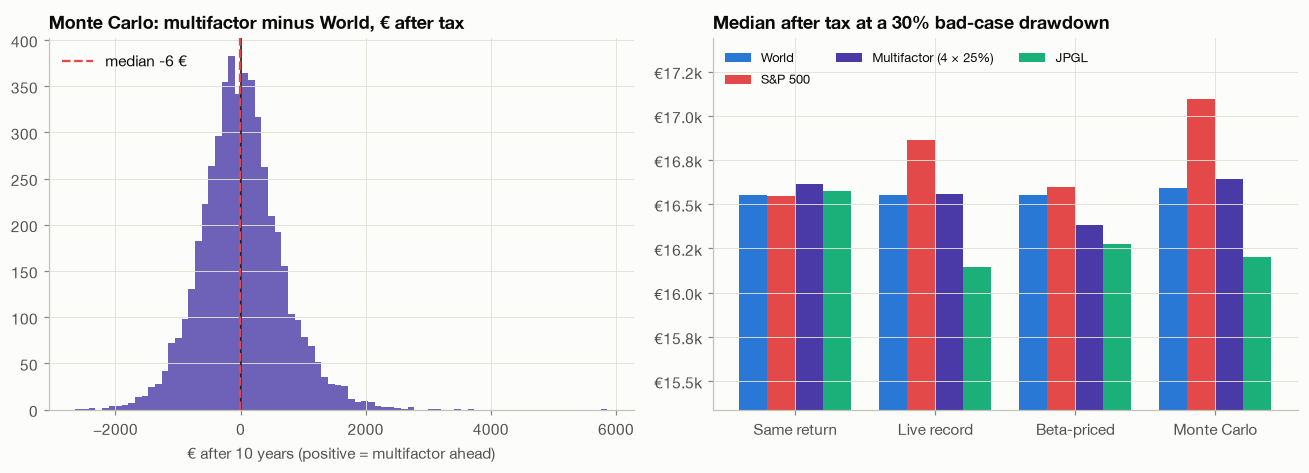

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
d = RES[(S_MC, "Multifactor (4 × 25%)")]["after_tax"] - RES[(S_MC, "World")]["after_tax"]
axes[0].hist(d, bins=80, color=SLOT[4], alpha=0.8)
axes[0].axvline(0, color=INK, lw=1)
axes[0].axvline(np.median(d), color=SLOT[5], lw=1.5, ls="--", label=f"median {np.median(d):+,.0f} €")
axes[0].set_title("Monte Carlo: multifactor minus World, € after tax")
axes[0].set_xlabel("€ after 10 years (positive = multifactor ahead)"); axes[0].legend(loc="upper left")
x_ = np.arange(len(PATHS)); wd = 0.2
for j, (e, c) in enumerate(zip(EQO, [SLOT[0], SLOT[5], SLOT[4], SLOT[1]])):
    axes[1].bar(x_ + (j - 1.5) * wd, med.loc[list(PATHS), e], wd, color=c, label=e)
axes[1].set_xticks(x_, list(PATHS)); axes[1].set_ylim(med.min().min() * 0.95, med.max().max() * 1.02)
axes[1].yaxis.set_major_formatter(eur_k); axes[1].set_title("Median after tax at a 30% bad-case drawdown")
axes[1].legend(loc="upper left", ncols=3, fontsize=8.5)
plt.tight_layout(); plt.show()

### 4a · Real history, no assumptions

The simulation re-centres returns on assumptions. As a check that does not, run the actual plan through
**every real 10-year window** from 1999 (monthly start dates), at the weights found above (same-return
scenario). History flatters whatever happened to work in 1999–2026, so this is a check of shapes and
crises, not of expected return.

In [11]:
HW, starts = D.historical_windows(X, 10, 1)
rows = {}
for e, em in EQO.items():
    we = CMP.loc[(S_SAME, e), "Equity weight"]
    res, o = run(HW, wmix(em, we))
    at = res["after_tax"]
    rows[e] = {"Equity weight": we, "Windows": len(at), "Median €": np.median(at), "Worst €": at.min(),
               "Best €": at.max(), "Worst-window start": f"{starts[int(np.argmin(at))]:%Y-%m}",
               "Worst drawdown": -res["max_dd"].min(), "P(end < paid in)": (at < 13000).mean()}
HWT = pd.DataFrame(rows).T
display(HWT.style.format({"Equity weight": "{:.0%}", "Windows": "{:.0f}", **EUR0(["Median €", "Worst €", "Best €"]),
                          "Worst drawdown": "{:.1%}", "P(end < paid in)": "{:.0%}"}))

,Equity weight,Windows,Median €,Worst €,Best €,Worst-window start,Worst drawdown,P(end < paid in)
World,52%,213,"€17,782","€12,320","€20,267",1999-03,25.9%,2%
S&P 500,51%,213,"€18,925","€11,999","€22,158",1999-03,23.7%,3%
Multifactor (4 × 25%),57%,213,"€17,728","€12,897","€20,978",1999-03,29.1%,1%
JPGL,60%,213,"€17,396","€12,472","€20,604",1999-03,29.0%,1%


### 4b · The practical costs of four sleeves instead of one

The simulation already counts the extra fund cost (factor TERs of 0.25% against 0.06% for the World fund,
the same 0.19% offset taken off each), the three extra €1 initial orders and per-sleeve taxation. Two more
things are not numbers in the table:

- **Drift.** With no selling, the four sleeves drift apart; below, how far apart after 10 years.
- **Tax loss stranding.** In Italy an ETF loss is a *reddito diverso* and cannot offset an ETF gain (a
  *reddito di capitale*). With four sleeves, one can end at a loss while the others pay full tax on their gains.

In [12]:
res = RES[(S_SAME, "Multifactor (4 × 25%)")]
sv = res["sleeve_value"]
ix = [COLS.index(k) for k in FAC]
share = sv[:, ix] / sv[:, ix].sum(axis=1, keepdims=True)
DR = pd.DataFrame({"Median share at year 10": np.median(share, axis=0), "5th pct": np.percentile(share, 5, axis=0),
                   "95th pct": np.percentile(share, 95, axis=0)}, index=[FLAB[k] for k in FAC])
display(DR.style.format("{:.0%}"))
gain = sv[:, ix] - res["sleeve_basis"][:, ix]
stranded = np.where(gain < 0, -gain, 0).sum(axis=1)
lost_tax = np.minimum(stranded, np.maximum(gain, 0).sum(axis=1)) * 0.26
print(f"At least one factor sleeve ends at a loss on {(gain < 0).any(axis=1).mean():.0%} of paths; the tax that loss "
      f"could have saved if it were offsettable: median €{np.median(lost_tax):.0f}, 95th pct €{np.percentile(lost_tax, 95):.0f}.")

,Median share at year 10,5th pct,95th pct
Momentum,25%,20%,31%
Quality,25%,21%,28%
Value,25%,19%,34%
Min Vol,25%,19%,30%


At least one factor sleeve ends at a loss on 23% of paths; the tax that loss could have saved if it were offsettable: median €0, 95th pct €62.


## 5 · Should part of the bond sleeve go into JPGL?

JPGL's appeal is real: over its own years, volatility 13.3% against 14.5% for World, beta about 0.83, and in
2022 it fell far less than both World and euro bonds. The question is whether **moving some of the bond
sleeve into it** improves the plan. Two things to separate:

1. **JPGL is equity.** In its own years its correlation with World was 0.90 and with euro government bonds
   +0.39 (both fell in 2022); over the full proxy history, 0.95 and about zero. In a deep equity crash it
   falls with equities; bonds do not. Its gains are taxed at 26%, not 12.5%.
2. **Any move from bonds into equity raises risk.** So it is done two ways: **naively** (keep World at 50%,
   move 10/20/30 points of bonds into JPGL — what it does to the risk level) and **at constant risk**
   (hold the 30% bad-case drawdown and let the weights adjust — whether JPGL earns its place on merit).

In [13]:
CR = D.crisis_table(H_[["World", "JPGL", "EUR Govt 7-10"]])
CR = CR.dropna(how="all").loc[["Dot-com 2000-03", "GFC 2007-09", "Euro crisis 2011", "COVID 2020", "Inflation 2022"]]
CR.columns = ["World", "JPGL (proxy before 2019-11)", "Euro govt 7-10"]
display(CR.style.format("{:+.1%}").background_gradient(cmap="RdYlGn", vmin=-0.5, vmax=0.2, axis=None))
live = H_.loc[jp.index[0]:, ["World", "JPGL", "EUR Govt 7-10"]]
print(f"Its own live years only ({live.index[0]:%Y-%m} → {live.index[-1]:%Y-%m}): volatility "
      + ", ".join(f"{k} {v:.1%}" for k, v in (live.std() * np.sqrt(12)).items())
      + f"; correlation JPGL–bonds {live['JPGL'].corr(live['EUR Govt 7-10']):+.2f}, JPGL–World {live['JPGL'].corr(live['World']):.2f}.")

,World,JPGL (proxy before 2019-11),Euro govt 7-10
Dot-com 2000-03,-53.8%,-39.4%,+26.9%
GFC 2007-09,-47.5%,-43.4%,+9.6%
Euro crisis 2011,-11.1%,-5.4%,+5.4%
COVID 2020,-19.8%,-21.7%,-3.0%
Inflation 2022,-13.3%,-7.2%,-17.8%


Its own live years only (2019-11 → 2026-09): volatility World 14.5%, JPGL 13.3%, EUR Govt 7-10 6.3%; correlation JPGL–bonds +0.39, JPGL–World 0.90.


In [14]:
BASE_W = 0.50   # portfolio_choice §7: World 50 / euro govt 7-10 50
def w3(world, jpgl):
    d = {"World": world, "JPGL": jpgl, "EUR Govt 7-10": 1 - world - jpgl}
    return np.array([d.get(c, 0.0) for c in COLS])

naive = {}
for cut in (0.0, 0.10, 0.20, 0.30):
    r_ = {}
    for s, P in PATHS.items():
        res, o = run(P, w3(BASE_W, cut))
        r_[f"Median € ({s})"] = o["Median €"]
        if s == S_SAME:
            v = res["values"]
            r_ |= {"Bad-case drawdown": -o["p5 max DD"], "Bad case p5 €": o["Bad case p5 €"], "P(end < paid in)": o["P(end < paid in)"],
                   "1-in-20 worst 12-month fall €": np.percentile((v[:, 12:] - v[:, :-12] - 1200).min(axis=1), 5)}
    naive[f"World 50 / JPGL {cut:.0%} / bonds {1 - BASE_W - cut:.0%}"] = r_
NV = pd.DataFrame(naive).T
display(NV.style.format(EUR0([c for c in NV if "€" in c]) | P1(["Bad-case drawdown", "P(end < paid in)"]))
        .background_gradient(cmap="Reds", subset=["Bad-case drawdown"]))
print(f"The risk level is {RISK_T:.0%}. The current plan sits at {NV['Bad-case drawdown'].iloc[0]:.1%}; each 10 points moved "
      f"from bonds to JPGL adds about {NV['Bad-case drawdown'].diff().mean():.0%} of bad-case drawdown.")

,Median € (Same return),Bad-case drawdown,Bad case p5 €,P(end < paid in),1-in-20 worst 12-month fall €,Median € (Live record),Median € (Beta-priced),Median € (Monte Carlo)
World 50 / JPGL 0% / bonds 50%,"€16,520",29.1%,"€13,001",5.0%,"€-2,862","€16,520","€16,520","€16,543"
World 50 / JPGL 10% / bonds 40%,"€16,725",33.8%,"€12,634",6.9%,"€-3,367","€16,652","€16,674","€16,664"
World 50 / JPGL 20% / bonds 30%,"€16,925",38.7%,"€12,142",9.0%,"€-3,997","€16,777","€16,821","€16,771"
World 50 / JPGL 30% / bonds 20%,"€17,116",43.7%,"€11,581",10.8%,"€-4,669","€16,895","€16,960","€16,870"


The risk level is 30%. The current plan sits at 29.1%; each 10 points moved from bonds to JPGL adds about 5% of bad-case drawdown.


**At constant risk.** Now the equity part is a mix of World and JPGL — JPGL's share of the equity from 0 to
100% — and the total equity weight is dialled back to a 30% bad-case drawdown each time. Because JPGL is
less volatile than World, the dial lets total equity rise and **the bond sleeve shrinks**: this is exactly
"cut part of the bond sleeve into JPGL", done without taking more risk. The question is whether the
outcome improves.

In [15]:
QS = [0.0, 0.25, 0.5, 0.75, 1.0]
cr = {}
for q in QS:
    r_ = {}
    for s, P in PATHS.items():
        f_ = lambda w: w3(w * (1 - q), w * q)
        we = weight_for(P, f_)
        res, o = run(P, f_(we))
        RES[(s, f"q{q}")] = res
        r_[f"Median € ({s})"] = o["Median €"]
        if s == S_SAME:
            r_ = {"World": we * (1 - q), "JPGL": we * q, "Bonds": 1 - we, **r_,
                  "Bad case p5 €": o["Bad case p5 €"], "P(end < paid in)": o["P(end < paid in)"]}
    cr[f"JPGL {q:.0%} of equity"] = r_
CRT = pd.DataFrame(cr).T
mcols = [c for c in CRT if c.startswith("Median") and S_MC not in c]
CRT["Worst-scenario median €"] = CRT[mcols].min(axis=1)
for c in [c for c in CRT if c.startswith("Median")]:
    CRT[c.replace("Median €", "vs no JPGL")] = CRT[c] - CRT[c].iloc[0]
display(CRT[["World", "JPGL", "Bonds"] + [c for c in CRT if c.startswith("Median")] + ["Worst-scenario median €", "Bad case p5 €", "P(end < paid in)"]]
        .style.format(P1(["World", "JPGL", "Bonds", "P(end < paid in)"]) | EUR0([c for c in CRT if "€" in c]))
        .background_gradient(cmap="Greens", subset=["Worst-scenario median €"]))
print("Gain or loss against the current plan (World + bonds, JPGL 0%), same 30% risk:")
display(CRT[[c for c in CRT if c.startswith("vs no JPGL")]].style.format("{:+,.0f} €")
        .background_gradient(cmap="RdYlGn", vmin=-400, vmax=400, axis=None))
print("Weights shown for the same-return scenario; each scenario is dialled separately.")

,World,JPGL,Bonds,Median € (Same return),Median € (Live record),Median € (Beta-priced),Median € (Monte Carlo),Worst-scenario median €,Bad case p5 €,P(end < paid in)
JPGL 0% of equity,51.6%,0.0%,48.4%,"€16,553","€16,553","€16,553","€16,592","€16,553","€12,933",5.2%
JPGL 25% of equity,40.4%,13.5%,46.1%,"€16,609","€16,509","€16,536","€16,527","€16,509","€12,930",5.5%
JPGL 50% of equity,28.0%,28.0%,44.0%,"€16,596","€16,398","€16,455","€16,450","€16,398","€12,906",5.5%
JPGL 75% of equity,14.5%,43.5%,42.0%,"€16,578","€16,270","€16,356","€16,336","€16,270","€12,905",5.4%
JPGL 100% of equity,0.0%,59.6%,40.4%,"€16,573","€16,146","€16,277","€16,205","€16,146","€12,921",5.5%


Gain or loss against the current plan (World + bonds, JPGL 0%), same 30% risk:


,vs no JPGL (Same return),vs no JPGL (Live record),vs no JPGL (Beta-priced),vs no JPGL (Monte Carlo)
JPGL 0% of equity,+0 €,+0 €,+0 €,+0 €
JPGL 25% of equity,+56 €,-44 €,-16 €,-65 €
JPGL 50% of equity,+43 €,-155 €,-98 €,-142 €
JPGL 75% of equity,+26 €,-283 €,-197 €,-256 €
JPGL 100% of equity,+21 €,-406 €,-275 €,-387 €


Weights shown for the same-return scenario; each scenario is dialled separately.


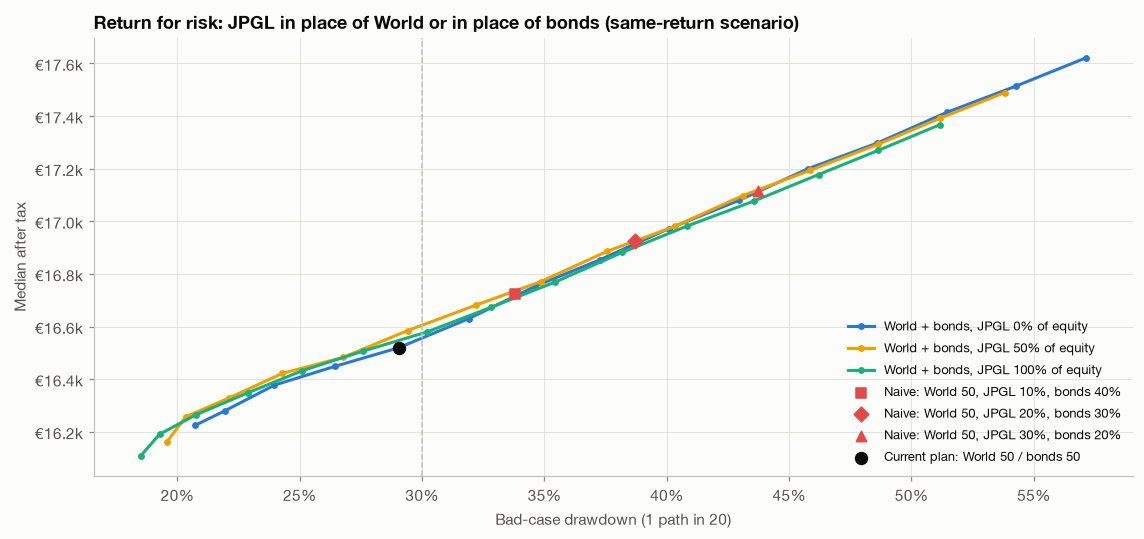

In [16]:
fig, ax = plt.subplots(figsize=(10.5, 5))
P = PATHS[S_SAME]
for q, c in zip([0.0, 0.5, 1.0], [SLOT[0], SLOT[2], SLOT[1]]):
    pts = [run(P, w3(w * (1 - q), w * q))[1] for w in WF]
    ax.plot([-p["p5 max DD"] for p in pts], [p["Median €"] for p in pts], color=c, marker="o", ms=3.5,
            label=f"World + bonds, JPGL {q:.0%} of equity")
for cut, mk in zip((0.10, 0.20, 0.30), ("s", "D", "^")):
    o = run(P, w3(BASE_W, cut))[1]
    ax.scatter(-o["p5 max DD"], o["Median €"], color=SLOT[5], marker=mk, s=46, zorder=4,
               label=f"Naive: World 50, JPGL {cut:.0%}, bonds {1 - BASE_W - cut:.0%}")
o = run(P, w3(BASE_W, 0))[1]
ax.scatter(-o["p5 max DD"], o["Median €"], color=INK, s=60, zorder=5, label="Current plan: World 50 / bonds 50")
ax.axvline(RISK_T, color=BASE, lw=1, ls="--")
ax.xaxis.set_major_formatter(pct0); ax.yaxis.set_major_formatter(eur_k)
ax.set_xlabel("Bad-case drawdown (1 path in 20)"); ax.set_ylabel("Median after tax")
ax.set_title("Return for risk: JPGL in place of World or in place of bonds (same-return scenario)")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()

## 6 · The answers

### World or the multifactor blend?

| At a 30% bad-case drawdown | World | S&P 500 | Multifactor (4 × 25%) |
|---|---|---|---|
| Equity weight needed | 52% | 51–52% | 57% (it is less volatile, so it can hold more) |
| Median after tax: same return / live record / beta-priced | €16,553 / €16,553 / €16,553 | €16,548 / €16,862 / €16,600 | €16,617 / €16,559 / €16,381 |
| Median after tax, Monte Carlo | €16,592 | €17,098 | €16,644 |
| Spread between scenarios | €0 | €313 | €235 |
| Ends ahead of World, path by path (Monte Carlo) | — | 77% of paths, median +€551 | 50% of paths, median −€6 |
| Real 10-year windows since 1999: median / worst | €17,782 / €12,320 | €18,925 / €11,999 | €17,728 / €12,897 |
| Funds and savings plans | 2 | 2 | 5 |

- **The blend is a coin flip against World, not an improvement.** At the median it is **+€64 if every sleeve
  earns the same, +€6 if factors keep their live record, −€172 if lower risk is paid for with lower return**
  (beta-priced), and +€52 in the Monte Carlo, where it ends ahead on half the paths. Measured against MSCI World
  — the universe it is drawn from — its sleeves' live alphas are smaller than they looked against a broader
  market, and that is what removed the edge an earlier version of this notebook showed.
- **Where the case for it comes from.** Lower volatility (beta 0.86) lets it carry 5 more points of equity at
  the same risk. Of the four factors, only momentum carries a material expected alpha (+3.2%/yr live, t 1.9,
  shrunk to +1.35% in the Monte Carlo). Value lost its backtest edge after launch (+5.4%/yr → −0.2%); quality
  (+0.4%) and min vol (+0.7% since 2014) earned little against World. The blend's live alpha is +1.1%/yr with a
  t-stat of 1.4 — not evidence.
- **In real history** the blend matched World's median and had a better worst window (€12,897 against
  €12,320): its crisis falls were shallower (dot-com −41% vs −54%).
- **Costs of running it**, all already in the numbers: TERs of 0.25% against 0.06% for the World fund, three
  extra €1 initial orders, and per-sleeve taxation (a loss on one factor ETF cannot offset a gain on another;
  worth under €62 in 95% of paths). The sleeves stay close to 25% each without rebalancing.

**The S&P 500 is the strongest number in the notebook — read it with care.** It leads the Monte Carlo (+€506
over World at the median, ahead on 77% of paths) and real history (6.9%/yr against 5.7%), and costs the least.
But both rest on one fact: US stocks beat the rest of the world from 2014 to 2026, largely because their
valuations rose. The Monte Carlo barely shrinks that record, for a mechanical reason — the S&P 500 is 70% of
World, so its return *relative* to World is smooth and its alpha looks precise (t 1.9), though it is one decade
of one region. Its worst-scenario median (€16,548) is World's; it falls more in a long bear market (worst real
window €11,999, the lowest of the four; max drawdown −62% against −57%); and it puts every euro of equity in one
country. Nothing in the data says the next decade repeats the last. It is a **bet on the US**, not a cheaper World.

**Verdict.** World is the robust choice: its outcome does not depend on which scenario is true. The S&P 500 is
the better bet *if* US outperformance continues, at the cost of concentration in one country. The 4 × 25% blend
buys a shallower ride through crashes (its history), not more money; if that matters to you more than
simplicity, it is defensible at **57% equity / 43% euro govt 7-10** — five savings plans, €14 in each factor
fund and €43 in bonds a month — but expect to trail World about half the time.

### Should part of the bond sleeve go into JPGL?

**No.** Two separate reasons:

1. **Moved naively, it is just more equity.** Every 10 points moved from bonds to JPGL raises the bad-case
   drawdown by about 5 points: 29% → 34% → 39% → 44%, and the 1-in-20 worst 12-month fall from −€2,900 to
   −€3,400, −€4,000, −€4,700. The extra median (+€90–200 per 10 points) is the ordinary reward for more risk,
   which a riskier World/bond mix delivers too. JPGL is not a bond substitute: in its own years its correlation
   with World is 0.90, and in a GFC-style crash it is modelled to fall about −43% where euro bonds rose 10%.
2. **At constant risk it does not earn its place.** Holding the 30% risk level and letting JPGL replace World
   (which shrinks the bond sleeve from 48% to 40%) changes the median by **+€20 to −€410**: a near-tie if every
   sleeve earns the same, a loss in every other scenario. Its live alpha against World is −0.7%/yr (t −0.3):
   its low volatility is real, but so far it has been paid for, not earned. It also behaves mostly like a
   min-vol fund (fitted mix: 46% min vol, 30% World, 20% value).

**Why it looks low-risk on fund pages.** The 8% one-year volatility on justETF is one calm year; over its
whole life it was 13.3% against 14.5% for World — a modest difference. Its 2022 fall (−5% to −7%) was small
because value and min vol did well that year, not because it behaves like a bond.

## 7 · Refining the multifactor choice

Three follow-up questions: **(a)** is there one ETF that holds the blend (so a losing factor nets against
the winners inside the fund, instead of stranding a tax loss)? **(b)** is there a better mix of the four
factors, possibly leaving some out? **(c)** how diversified across sectors and regions is each option, and
does that diversification actually protect in a crisis?

### 7a · One fund instead of four

**No UCITS ETF holds the four MSCI factor indexes in equal parts.** The single-fund multifactor ETFs on the
market each run their own recipe:

| Fund | ISIN | TER | Approach | Notes |
|---|---|---|---|---|
| JPMorgan Global Equity Multi-Factor (JPGL) | IE00BJRCLL96 | 0.19% | Value, momentum, quality, low volatility; equal risk across regional sectors | Analysed in §5; acc |
| HSBC Multi-Factor Worldwide Equity (H41J) | IE00BKZGB098 | 0.25% | Value, momentum, quality, low risk, size; includes emerging markets | **Distributing**: dividends taxed every year |
| iShares World Equity Multifactor (IFSW) | IE00BZ0PKT83 | 0.30% | Was MSCI World Diversified Multiple-Factor; **since 2025-01 a STOXX index** (four factors, screened) | Acc; most expensive |
| Invesco Global Enhanced Equity (IQGA) | IE000TZ4SIN6 | 0.24% | **Active** quant: value, quality, momentum, close to MSCI World | Acc; launched 2025-05, no record |
| Avantis Global Equity (AVWC) | IE000RJECXS5 | 0.22% | **Active**: value + profitability, all caps | Acc; launched 2024-09, no record |

Below, the two with a long enough record, converted to EUR, against World and the 4 × 25% MSCI blend on the
same months.

**How much is the tax netting worth?** §4b measured it: with four sleeves, at least one ends at a loss on
about a quarter of paths, but the tax that loss could have saved is **€0 at the median and €62 at the 95th
percentile** — small, because a 10-year plan in four equity funds rarely leaves one underwater at the end.
(On Trade Republic Italy, regime amministrato since 2025-01, a stranded ETF loss is not lost entirely: it sits
in the *zainetto fiscale* for four years and can offset gains on single shares, ETCs or certificates.)

In [17]:
fx = pf.month_end(pf.ecb_series("EXR/D.USD.EUR.SP00.A"), END)
ONE = {"HSBC Multi-Factor Worldwide (HWWD)": "HWWD.L", "iShares World Multifactor (IFSW)": "IFSW.L"}
rows = {}
for nm, t in ONE.items():
    r = pf.to_eur(D.etf_returns(t, END), fx)
    x = pd.concat([r.rename("f"), eq["World"].rename("w"), eq[FAC].mean(axis=1).rename("b")], axis=1).dropna()
    for lab, s in {nm: x["f"], "  World, same months": x["w"], "  4 × 25% MSCI blend, same months": x["b"]}.items():
        st, ab = pf.perf_stats(s), D.alpha_beta(s, MKT, RF)
        rows[(nm, lab)] = {"From": f"{x.index[0]:%Y-%m}", "CAGR": st["CAGR"], "Volatility": st["Volatility"], "Beta": ab["Beta"],
                           "Alpha /yr": ab["Alpha /yr"], "Alpha t-stat": ab["Alpha t-stat"], "2022": (1 + s.loc["2022"]).prod() - 1}
OF = pd.DataFrame(rows).T.droplevel(0)
OF.loc[OF.index.str.contains("World, same months"), ["Alpha /yr", "Alpha t-stat"]] = np.nan   # World is the market here
display(OF.style.format(P1(["CAGR", "Volatility", "Alpha /yr", "2022"]) | {"Beta": "{:.2f}", "Alpha t-stat": "{:+.1f}"}, na_rep="—"))
print("Fund returns are after their own costs; the MSCI blend is index level (before about 0.25% of fund cost).")

,From,CAGR,Volatility,Beta,Alpha /yr,Alpha t-stat,2022
HSBC Multi-Factor Worldwide (HWWD),2014-12,11.3%,12.9%,0.92,0.4%,+0.5,-12.6%
"World, same months",2014-12,11.9%,13.5%,1.00,—,—,-12.8%
"4 × 25% MSCI blend, same months",2014-12,11.6%,12.2%,0.87,1.1%,+1.4,-8.5%
iShares World Multifactor (IFSW),2016-02,11.8%,12.8%,0.92,0.1%,+0.1,-10.2%
"World, same months",2016-02,12.7%,13.1%,1.00,—,—,-12.8%
"4 × 25% MSCI blend, same months",2016-02,11.9%,11.7%,0.86,0.8%,+1.0,-8.5%


Fund returns are after their own costs; the MSCI blend is index level (before about 0.25% of fund cost).


### 7b · A better mix of factors?

Every mix of the four in steps of 25%, plus thirds (one factor left out), plus mixes with World or JPGL, each
dialled to the 30% risk level in each scenario. Ranked on the **Monte Carlo median**; the worst-scenario
median and the share of Monte Carlo paths that end ahead of World are shown alongside. Next to each euro figure, the
same outcome as an **annual return**: the money-weighted rate (IRR) at which €1,000 up front plus €100 a month
grows to that after-tax value in ten years.

**A warning before reading it.** The differences between mixes are €0–300 over ten years, the same size
as the uncertainty in the assumptions behind them, and the top rows are top because momentum is the only
factor whose live alpha against World survives the shrinkage (the S&P 500, at the very top, is a regional bet
— see §6). Picking the top row is choosing on noise; the table is for seeing which *shapes* of mix hold up
across scenarios.

In [18]:
import itertools
M_, Q_, V_, MV_ = FAC
MIX = {}
for q in itertools.product(range(5), repeat=4):
    if sum(q) == 4:
        MIX["Mom/Qual/Val/MinVol " + "/".join(str(25 * v) for v in q)] = {f: v / 4 for f, v in zip(FAC, q) if v}
for d in FAC:
    MIX[f"Thirds without {FLAB[d]}"] = {f: 1 / 3 for f in FAC if f != d}
MIX |= {"World + Mom + Val, thirds": {"World": 1 / 3, M_: 1 / 3, V_: 1 / 3},
        "Mom + Qual + Val + JPGL, 25% each": {M_: .25, Q_: .25, V_: .25, "JPGL": .25},
        "World": {"World": 1}, SP: {SP: 1}, "JPGL": {"JPGL": 1}}
mres = {}
for nm, em in MIX.items():
    r_ = {}
    for s, P in PATHS.items():
        we = weight_for(P, lambda w: wmix(em, w))
        res, o = run(P, wmix(em, we))
        r_[f"Median € ({s})"] = o["Median €"]
        if s == S_MC:
            r_["Equity weight"] = we
            r_["Ahead of World (MC paths)"] = (res["after_tax"] > RES[(S_MC, "World")]["after_tax"]).mean()
    mres[nm] = r_
MX = pd.DataFrame(mres).T
sc3 = [f"Median € ({s})" for s in (S_SAME, S_LIVE, S_BETA)]
MX["Worst-scenario median €"] = MX[sc3].min(axis=1)
MX["Spread between scenarios €"] = MX[sc3].max(axis=1) - MX["Worst-scenario median €"]
MX = MX.sort_values(f"Median € ({S_MC})", ascending=False)
irr = lambda v: D.irr_annual(np.asarray(v, float), 1000, 100, H)      # annual money-weighted return after tax
for c in [f"Median € ({S_MC})", "Worst-scenario median €"] + sc3:
    MX[c.replace("€", "%/yr")] = irr(MX[c])
order = [f"Median € ({S_MC})", "Ahead of World (MC paths)", "Worst-scenario median €", "Spread between scenarios €"] + sc3
MX = MX[["Equity weight"] + [x for c in order for x in ([c, c.replace("€", "%/yr")] if "€" in c and c.replace("€", "%/yr") in MX else [c])]]
display(MX.style.format({"Equity weight": "{:.0%}", "Ahead of World (MC paths)": "{:.0%}", **EUR0([c for c in MX if "€" in c]),
                         **{c: "{:.2%}" for c in MX if "%/yr" in c}})
        .background_gradient(cmap="Greens", subset=[f"Median € ({S_MC})", "Worst-scenario median €"])
        .background_gradient(cmap="Reds", subset=["Spread between scenarios €"]))

,Equity weight,Median € (Monte Carlo),Median %/yr (Monte Carlo),Ahead of World (MC paths),Worst-scenario median €,Worst-scenario median %/yr,Spread between scenarios €,Median € (Same return),Median %/yr (Same return),Median € (Live record),Median %/yr (Live record),Median € (Beta-priced),Median %/yr (Beta-priced)
S&P 500,52%,"€17,098",5.03%,77%,"€16,548",4.44%,€313,"€16,548",4.44%,"€16,862",4.78%,"€16,600",4.50%
Mom/Qual/Val/MinVol 100/0/0/0,47%,"€16,857",4.78%,63%,"€16,347",4.22%,€509,"€16,474",4.36%,"€16,856",4.78%,"€16,347",4.22%
Mom/Qual/Val/MinVol 75/0/25/0,50%,"€16,828",4.75%,64%,"€16,423",4.30%,€382,"€16,529",4.42%,"€16,805",4.72%,"€16,423",4.30%
Mom/Qual/Val/MinVol 75/25/0/0,51%,"€16,818",4.74%,63%,"€16,392",4.27%,€442,"€16,531",4.42%,"€16,835",4.75%,"€16,392",4.27%
Mom/Qual/Val/MinVol 50/25/25/0,52%,"€16,778",4.69%,62%,"€16,470",4.36%,€292,"€16,566",4.46%,"€16,762",4.68%,"€16,470",4.36%
Mom/Qual/Val/MinVol 75/0/0/25,53%,"€16,763",4.68%,58%,"€16,300",4.17%,€441,"€16,564",4.46%,"€16,741",4.65%,"€16,300",4.17%
Mom/Qual/Val/MinVol 50/50/0/0,53%,"€16,757",4.67%,62%,"€16,422",4.30%,€339,"€16,542",4.44%,"€16,761",4.67%,"€16,422",4.30%
Thirds without Min Vol,53%,"€16,734",4.65%,57%,"€16,488",4.38%,€199,"€16,579",4.48%,"€16,687",4.59%,"€16,488",4.38%
Mom/Qual/Val/MinVol 25/50/25/0,54%,"€16,730",4.64%,56%,"€16,492",4.38%,€192,"€16,591",4.49%,"€16,684",4.59%,"€16,492",4.38%
Mom/Qual/Val/MinVol 50/0/50/0,50%,"€16,724",4.63%,58%,"€16,463",4.35%,€240,"€16,542",4.44%,"€16,703",4.61%,"€16,463",4.35%


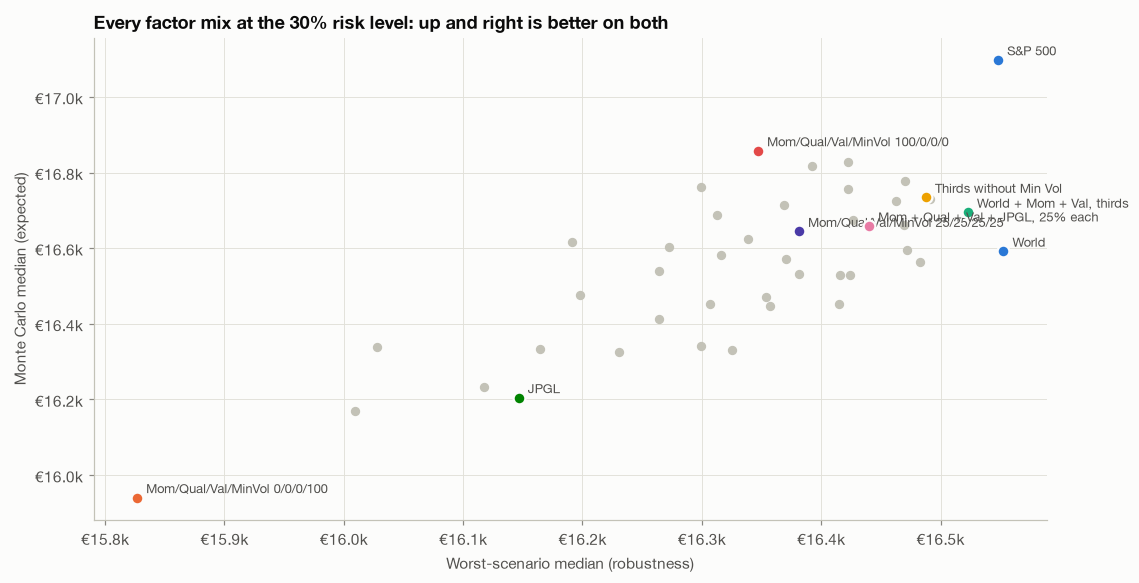

In [19]:
fig, ax = plt.subplots(figsize=(10.5, 5.4))
x_, y_ = MX["Worst-scenario median €"], MX[f"Median € ({S_MC})"]
ax.scatter(x_, y_, s=26, color=BASE, zorder=2)
SHOW = {"Mom/Qual/Val/MinVol 25/25/25/25": SLOT[4], "Thirds without Min Vol": SLOT[2], "World + Mom + Val, thirds": SLOT[1],
        "Mom + Qual + Val + JPGL, 25% each": SLOT[6], "Mom/Qual/Val/MinVol 100/0/0/0": SLOT[5], "Mom/Qual/Val/MinVol 0/0/0/100": SLOT[7],
        "World": SLOT[0], SP: SLOT[0], "JPGL": SLOT[3]}
for k, c in SHOW.items():
    ax.scatter(x_[k], y_[k], s=60, color=c, edgecolor=SURFACE, lw=1.5, zorder=3)
    ax.annotate(k, (x_[k], y_[k]), xytext=(6, 3), textcoords="offset points", fontsize=8.5, color=INK2)
ax.xaxis.set_major_formatter(eur_k); ax.yaxis.set_major_formatter(eur_k)
ax.set_xlabel("Worst-scenario median (robustness)"); ax.set_ylabel("Monte Carlo median (expected)")
ax.set_title("Every factor mix at the 30% risk level: up and right is better on both")
plt.tight_layout(); plt.show()

**The same mixes in real history.** No assumptions: the actual monthly returns, after fund cost.

1. **The plan through every real 10-year window.** €1,000 + €100 a month into each mix at the equity weight
   found above (Monte Carlo column), the rest in euro government 7-10, taxed at the end. Windows start every
   month from 1999-02. Two views: **all windows** (213, starting 1999-02 → 2016-10), and **live windows only**
   (start 2014-12 or later, when all four factor indexes had been launched — 23 windows, heavily overlapping,
   all inside one bull market).
2. **The equity mix on its own** (rebalanced monthly), full history and live years only.

**Read with care.** Before each factor index's launch date its history is a backtest, built knowing what had
worked (§2: enhanced value earned +4.5%/yr before launch, +0.1% after). The all-windows view therefore
flatters the factor mixes; the live view is honest but short. JPGL before 2019-11 is the fitted proxy.

In [20]:
LIVE0 = "2014-12"
live_w = np.array([s >= pd.Timestamp(LIVE0) for s in starts])
hrows = {}
for nm, em in MIX.items():
    we = MX.loc[nm, "Equity weight"]
    res, _ = run(HW, wmix(em, we))
    at = res["after_tax"]
    irr_ = D.irr_annual(at, 1000, 100, H)
    d = at - run(HW, wmix(MIX["World"], MX.loc["World", "Equity weight"]))[0]["after_tax"]
    hrows[nm] = {"Equity weight": we, "Median €": np.median(at), "Median %/yr": np.median(irr_),
                 "Worst €": at.min(), "Worst %/yr": irr_.min(), "Best %/yr": irr_.max(),
                 "Worst drawdown": -res["max_dd"].min(), "Windows ahead of World": (d > 0).mean(),
                 "Live windows: median %/yr": np.median(irr_[live_w]), "Live windows: worst %/yr": irr_[live_w].min(),
                 "Live windows ahead of World": (d[live_w] > 0).mean()}
HX = pd.DataFrame(hrows).T.sort_values("Median %/yr", ascending=False)
print(f"Every real 10-year window: {len(starts)} in all ({starts[0]:%Y-%m} → {starts[-1]:%Y-%m}), {live_w.sum()} starting {LIVE0} or later.")
display(HX.style.format({"Equity weight": "{:.0%}", **EUR0(["Median €", "Worst €"]), "Worst drawdown": "{:.1%}",
                         **{c: "{:.2%}" for c in HX if "%/yr" in c}, **{c: "{:.0%}" for c in HX if "ahead" in c}})
        .background_gradient(cmap="Greens", subset=["Median %/yr", "Live windows: median %/yr"])
        .background_gradient(cmap="RdYlGn", subset=["Worst %/yr", "Live windows: worst %/yr"]))

Every real 10-year window: 213 in all (1999-02 → 2016-10), 23 starting 2014-12 or later.


,Equity weight,Median €,Median %/yr,Worst €,Worst %/yr,Best %/yr,Worst drawdown,Windows ahead of World,Live windows: median %/yr,Live windows: worst %/yr,Live windows ahead of World
S&P 500,52%,"€18,945",6.88%,"€11,986",-1.53%,9.68%,23.7%,84%,6.81%,5.46%,100%
Mom/Qual/Val/MinVol 25/75/0/0,56%,"€18,333",6.29%,"€12,558",-0.65%,8.91%,25.7%,100%,5.89%,4.93%,100%
Mom/Qual/Val/MinVol 50/50/0/0,53%,"€18,329",6.29%,"€12,834",-0.24%,9.02%,25.7%,100%,5.94%,5.00%,100%
Mom/Qual/Val/MinVol 0/100/0/0,57%,"€18,258",6.22%,"€12,308",-1.03%,8.89%,25.3%,98%,5.78%,4.79%,87%
Mom/Qual/Val/MinVol 75/25/0/0,51%,"€18,249",6.21%,"€13,140",0.20%,9.08%,25.3%,99%,5.96%,5.00%,100%
Mom/Qual/Val/MinVol 100/0/0/0,47%,"€18,181",6.14%,"€13,479",0.68%,9.18%,25.1%,95%,5.87%,4.91%,96%
Mom/Qual/Val/MinVol 75/0/0/25,53%,"€18,155",6.12%,"€13,137",0.20%,9.28%,26.2%,93%,5.62%,4.89%,74%
Mom/Qual/Val/MinVol 50/25/0/25,56%,"€18,065",6.03%,"€12,800",-0.29%,9.05%,26.3%,97%,5.60%,4.92%,70%
Mom/Qual/Val/MinVol 75/0/25/0,50%,"€18,030",5.99%,"€13,454",0.64%,8.70%,27.4%,85%,5.63%,4.53%,48%
Mom/Qual/Val/MinVol 50/25/25/0,52%,"€17,982",5.94%,"€13,183",0.26%,8.70%,27.9%,87%,5.57%,4.48%,52%


In [21]:
EH = H_[["World", SP] + FAC + ["JPGL"]]
SEL = ["World", SP, "Mom/Qual/Val/MinVol 25/25/25/25", "Thirds without Min Vol", "Mom/Qual/Val/MinVol 50/25/25/0",
       "World + Mom + Val, thirds", "Mom + Qual + Val + JPGL, 25% each", "Mom/Qual/Val/MinVol 100/0/0/0",
       "Mom/Qual/Val/MinVol 0/0/0/100", "JPGL"]
erows = {}
for nm in SEL:
    s = sum(EH[k] * v for k, v in MIX[nm].items())
    for per, sl in {"1999–2026": slice(None, END), f"Live {LIVE0} →": slice(LIVE0, END)}.items():
        x_ = s.loc[sl]
        st, ab = pf.perf_stats(x_), D.alpha_beta(x_, MKT, RF)
        xx = pd.concat([x_, MKT, RF], axis=1).dropna()
        ex_, em_ = xx.iloc[:, 0] - xx.iloc[:, 2], xx.iloc[:, 1] - xx.iloc[:, 2]
        resid = (ex_ - ab["Beta"] * em_).std() * np.sqrt(12)          # risk not explained by the market
        r_ = {"CAGR": st["CAGR"], "Volatility": st["Volatility"], "Max drawdown": st["Max drawdown"],
              "Beta": ab["Beta"], "Alpha /yr": ab["Alpha /yr"], "Alpha t-stat": ab["Alpha t-stat"],
              "Residual risk /yr": resid, "Alpha per unit of residual risk": ab["Alpha /yr"] / resid,
              "Sharpe": ex_.mean() * 12 / (xx.iloc[:, 0].std() * np.sqrt(12))}
        if per == "1999–2026":
            ct = D.crisis_table(x_.to_frame("x"))["x"]
            r_ |= {"Dot-com": ct["Dot-com 2000-03"], "GFC": ct["GFC 2007-09"]}
        r_ |= {"COVID": (1 + x_.loc["2020-02":"2020-03"]).prod() - 1, "2022": (1 + x_.loc["2022"]).prod() - 1}
        erows[(nm, per)] = r_
EX = pd.DataFrame(erows).T
EX.loc["World", ["Alpha t-stat", "Alpha per unit of residual risk"]] = np.nan   # World against itself: nothing to test
EX = EX.unstack(1)
EX = EX.reindex(columns=[c for c in EX.columns if not EX[c].isna().all()])
print("The equity mix alone, rebalanced monthly, after fund cost. Residual risk = volatility the market does not explain;")
print("alpha per unit of residual risk (the appraisal ratio) = how much alpha each point of departure from the market earned.")
display(EX.style.format("{:.1%}", na_rep="—").format("{:.2f}", na_rep="—", subset=[c for c in EX.columns if c[0] in ("Beta", "Alpha per unit of residual risk", "Sharpe")])
        .format("{:+.1f}", na_rep="—", subset=[c for c in EX.columns if c[0] == "Alpha t-stat"])
        .format("{:+.1%}", subset=[c for c in EX.columns if c[0] == "Alpha /yr"]))

The equity mix alone, rebalanced monthly, after fund cost. Residual risk = volatility the market does not explain;
alpha per unit of residual risk (the appraisal ratio) = how much alpha each point of departure from the market earned.


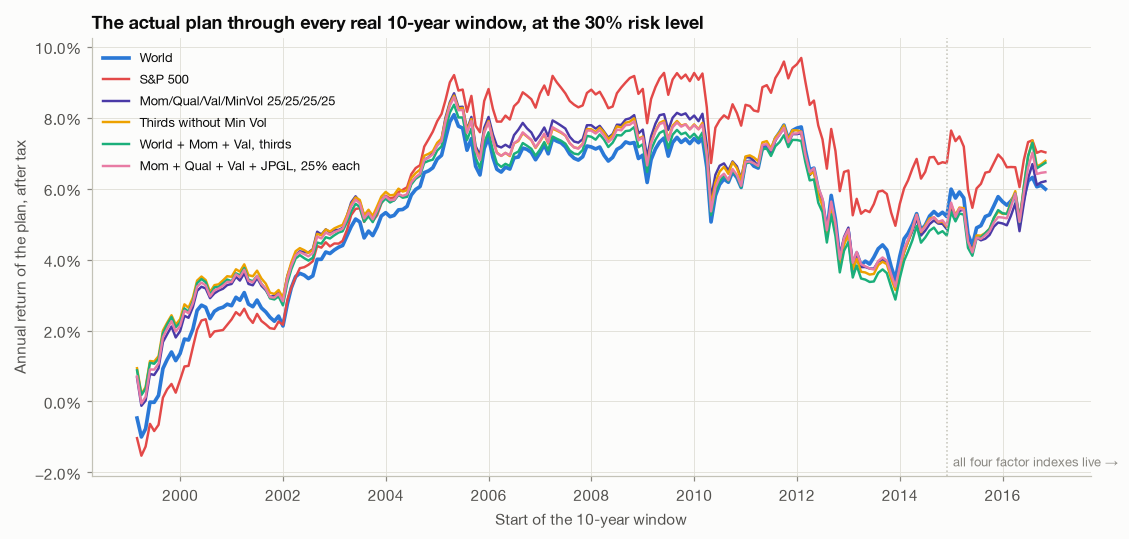

In [22]:
fig, ax = plt.subplots(figsize=(10.5, 5))
SH2 = {"World": SLOT[0], SP: SLOT[5], "Mom/Qual/Val/MinVol 25/25/25/25": SLOT[4], "Thirds without Min Vol": SLOT[2],
       "World + Mom + Val, thirds": SLOT[1], "Mom + Qual + Val + JPGL, 25% each": SLOT[6]}
for nm, c in SH2.items():
    irr_ = D.irr_annual(run(HW, wmix(MIX[nm], MX.loc[nm, "Equity weight"]))[0]["after_tax"], 1000, 100, H)
    ax.plot(starts, irr_, color=c, lw=1.6 if nm != "World" else 2.4, label=nm)
ax.axvline(pd.Timestamp(LIVE0), color=BASE, lw=1, ls=":")
ax.annotate("all four factor indexes live →", (pd.Timestamp(LIVE0), ax.get_ylim()[0]), xytext=(4, 6),
            textcoords="offset points", fontsize=8.5, color=MUTED)
ax.yaxis.set_major_formatter(pct1); ax.set_xlabel("Start of the 10-year window")
ax.set_ylabel("Annual return of the plan, after tax")
ax.set_title("The actual plan through every real 10-year window, at the 30% risk level")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

**What history says, and where it disagrees with the simulation.**

- **Over all 213 windows the 4 × 25% blend tied World**: median 5.69%/yr against 5.74%, but a better worst
  window (−0.12%/yr against −1.00%, i.e. €12,915 against €12,323) and ahead of World in 75% of windows. Its
  edge in history is protection in the bad windows (those starting in 1999–2000), not a higher median.
- **In the live windows only (start 2014-12 or later) World won**: 5.74%/yr against 5.17% for the blend,
  which was ahead in only 22% of them. These 23 windows overlap almost completely and all end in 2024–26, after
  a decade led by US large-cap technology — exactly the stretch in which min vol (3.51%/yr) and value
  (3.80%/yr) trailed the market. It is one episode, not 23 independent tests.
- **History agrees with the simulation on momentum, and adds quality.** In real returns, **momentum and
  quality** were the strongest factor pair: every mix of only those two tops both the full-history and the live
  ranking among factor mixes, and beat World in 87–100% of windows. Value was the weakest live (alpha −0.2%/yr
  against World after launch). Min vol earned its keep only in crashes.
- **The S&P 500 beat everything in the median and nothing in the worst case.** 6.88%/yr median and ahead of World
  in every live window — but the worst window of all (−1.53%/yr, €11,986): it fell hardest in 2000–2002, when
  US technology led the market down.
- **Other mixes hold up only in the full record.** 50/25/25 and "thirds without min vol" beat World in 75–87%
  of all windows but only 30–52% of live windows; "World + momentum + value" in 71% and 30%. All had better
  worst windows than World.

**How to use this.** History cannot pick the mix either: the full record is half backtest, and the live record
is a single bull market. What it does confirm is consistent with §4: **factor mixes improved the bad windows
more than the typical one**, and the factors that helped most in the last decade (quality, momentum) are not
the ones that helped in 2000–2003 (value, min vol). An equal-weighted mix is the bet that does not need to
know which comes next. If you prefer to lean on the live decade, a **momentum + quality** tilt is what it
supports — with the warning from `portfolio_choice` §2c that past return rankings have tended to reverse.

**Reconciling history with the Monte Carlo.** They answer different questions. History is **one** sequence
of markets, with the average returns each sleeve happened to earn. The Monte Carlo keeps history's
month-to-month shapes but replaces the averages with today's assumptions — and their uncertainty. The two
disagree mainly because the averages differ:

In [23]:
cg_ = lambda r: (1 + r).prod() ** (12 / len(r)) - 1
AVG = pd.DataFrame({"Realised 1999–2026": X.apply(cg_), f"Realised live {LIVE0} →": X.loc[LIVE0:].apply(cg_),
                    "Monte Carlo centre": pd.Series(MC_MU)})
AVG.index = [FLAB.get(i, i) for i in AVG.index]
display(AVG.style.format("{:.1%}"))
print(f"Full history includes pre-launch backtests (value's {AVG.loc['Value', 'Realised 1999–2026']:.1%}); the live decade had "
      f"World at {AVG.loc['World', AVG.columns[1]]:.1%} against a {EQ_CMA:.1%} assumption, led by US large-cap technology,")
print(f"and euro bonds earning {AVG.loc['EUR Govt 7-10', AVG.columns[1]]:+.1%}/yr against today's {BOND_T:.1%} yield after fee.")

# Where does each historical outcome sit inside the Monte Carlo distribution of (mix − World)?
REC_M = ["Mom/Qual/Val/MinVol 25/25/25/25", "Mom/Qual/Val/MinVol 50/25/25/0", "Thirds without Min Vol",
         "World + Mom + Val, thirds", "Mom + Qual + Val + JPGL, 25% each"]
at_w_mc = run(PATHS[S_MC], wmix(MIX["World"], MX.loc["World", "Equity weight"]))[0]["after_tax"]
at_w_h = run(HW, wmix(MIX["World"], MX.loc["World", "Equity weight"]))[0]["after_tax"]
rows = {}
for nm in REC_M:
    we = MX.loc[nm, "Equity weight"]
    dmc = run(PATHS[S_MC], wmix(MIX[nm], we))[0]["after_tax"] - at_w_mc
    dh = run(HW, wmix(MIX[nm], we))[0]["after_tax"] - at_w_h
    r_ = {"MC: 5th pct €": np.percentile(dmc, 5), "MC: median €": np.median(dmc), "MC: 95th pct €": np.percentile(dmc, 95)}
    for lab, v in {"All windows, median": np.median(dh), "Live windows, median": np.median(dh[live_w]),
                   "Worst live window": dh[live_w].min()}.items():
        r_[f"{lab} €"] = v
        r_[f"{lab}: MC percentile"] = (dmc < v).mean()
    rows[nm] = r_
RC = pd.DataFrame(rows).T
print("\nGain over World after tax (€, 10 years): the Monte Carlo range, and where each real-history result falls in it")
display(RC.style.format({**{c: "{:+,.0f} €" for c in RC if c.endswith("€")}, **{c: "{:.0%}" for c in RC if "percentile" in c}})
        .background_gradient(cmap="RdYlGn", subset=[c for c in RC if "percentile" in c], vmin=0, vmax=1))

,Realised 1999–2026,Realised live 2014-12 →,Monte Carlo centre
World,7.4%,12.0%,6.4%
S&P 500,8.2%,14.1%,7.7%
Momentum,9.5%,14.6%,7.3%
Quality,7.8%,11.8%,6.3%
Value,10.0%,11.1%,6.2%
Min Vol,6.5%,8.0%,5.0%
JPGL,7.6%,10.2%,5.4%
EUR Govt 7-10,3.4%,0.3%,3.8%


Full history includes pre-launch backtests (value's 10.0%); the live decade had World at 12.0% against a 6.3% assumption, led by US large-cap technology,
and euro bonds earning +0.3%/yr against today's 3.8% yield after fee.



Gain over World after tax (€, 10 years): the Monte Carlo range, and where each real-history result falls in it


,MC: 5th pct €,MC: median €,MC: 95th pct €,"All windows, median €","All windows, median: MC percentile","Live windows, median €","Live windows, median: MC percentile",Worst live window €,Worst live window: MC percentile
Mom/Qual/Val/MinVol 25/25/25/25,"-1,005 €",-6 €,"+1,135 €",+484 €,79%,-314 €,29%,-706 €,11%
Mom/Qual/Val/MinVol 50/25/25/0,-854 €,+196 €,"+1,574 €",+603 €,73%,+10 €,39%,-196 €,26%
Thirds without Min Vol,-857 €,+108 €,"+1,446 €",+494 €,73%,-209 €,30%,-462 €,15%
"World + Mom + Val, thirds",-797 €,+110 €,"+1,470 €",+240 €,59%,-271 €,25%,-638 €,9%
"Mom + Qual + Val + JPGL, 25% each",-919 €,-7 €,"+1,178 €",+425 €,77%,-259 €,33%,-560 €,14%


**Reading it.**

- **Every historical result falls inside the Monte Carlo's 5th–95th range.** History does not contradict the
  model; it is one draw from it.
- **The full record was a lucky draw for factor mixes** (around the 73rd–79th percentile; 59th for World + momentum + value): partly genuine
  premia, partly backtest years designed with hindsight.
- **The live decade was an unlucky one** (medians at the 25th–38th percentile; the worst live windows down to the 9th): a strong US-technology market in
  which min vol and value lagged and euro bonds earned almost nothing. A 1-in-4 outcome, not an outlier — and its 23 windows are
  one episode, not 23 tests.

**How to use them together.**

1. **For expected outcomes, use the Monte Carlo.** It is the only one built on today's starting point (bond
   yields near 3.8%, not 2003's or 2014's) and on the honest uncertainty about factor premia.
2. **For the shape of crashes and the worst windows, use history.** It shows how each mix actually behaved
   in 2000–03, 2008, 2020 and 2022, which the Monte Carlo inherits but blends together.
3. **Prefer mixes that hold up in both, and treat a mix that wins in only one as a bet on that view.**
   Momentum/quality/value 50/25/25 is the most consistent of these five: the best Monte Carlo median of them
   (+€196 over World), and the only one roughly level with World in the live decade (+€10, 39th percentile).
   The 4 × 25% blend has the best crash record but is level with World in the Monte Carlo (−€6) and sat lowest
   in the live decade (29th percentile). Mixes of only momentum and quality, not in this table, led history
   outright among factor mixes (§7b).

### 7b-bis · Letting an optimiser choose the factor weights

The grid above steps in 25% increments. Here every mix of the four factors in **5% steps** (1,771 mixes) is
dialled to the 30% risk level and scored, and the best ones are kept. The score matters more than the search,
so there are three:

- **Monte Carlo median** — what to expect, with the expected returns themselves uncertain;
- **Worst-scenario median** — the lowest of the three scenario medians (same return / live record / beta-priced),
  i.e. the mix that is hurt least if its premise is wrong;
- **CE γ=4 in the Monte Carlo** — the certainty equivalent of a moderately risk-averse investor, which weighs the
  bad paths more than the median does.

To keep 1,771 × 4 dials affordable, the search runs on the first 1,500 simulated paths (same paths for every
mix, so the *ranking* is fair); the winners are then re-run on all 5,000.

**Then the blends you asked about**: the S&P 500 paired with one sleeve that behaves differently from it —
min vol, value, quality, momentum or JPGL — from 0% to 100% in 10% steps, scored the same way.

**How to read an optimiser here.** It maximises whatever it is given, noise included. The inputs differ between
factors by a few tenths of a percent a year, less than their own standard errors, so the "optimal" weights are a
sharp answer to a blurry question. What is worth reading is the **shape** — which weights stay in every winner —
and how *flat* the top is: if a hundred mixes sit within €30 of the best, none of them is meaningfully optimal.

In [24]:
NS = 1500
SUB = {s: P[:NS] for s, P in PATHS.items()}
WF_FAST = np.round(np.arange(0.40, 0.751, 0.05), 2)     # the search only needs the bracket every mix lands in (47–67%)

def weight_fast(P, wfun, t=RISK_T):
    dd, wg = rising([-D.outcome_summary(D.pac_paths_rule(P, wfun(w), TAX, "split"), H)["p5 max DD"] for w in WF_FAST], WF_FAST)
    return float(np.interp(t, dd, wg)) if dd[0] <= t <= dd[-1] else np.nan

def dial_sub(em, P):
    we = weight_fast(P, lambda w: wmix(em, w))
    if np.isnan(we):
        return np.nan, None
    return we, run(P, wmix(em, we))

def score(em, paths=SUB):
    out = {}
    for s, P in paths.items():
        we, r = dial_sub(em, P)
        if r is None:
            return None
        res, o = r
        out[s] = {"we": we, "med": o["Median €"], "ce": o["CE γ=4 €"], "at": res["after_tax"]}
    return {"Equity weight (MC)": out[S_MC]["we"], "Monte Carlo median €": out[S_MC]["med"],
            "Worst-scenario median €": min(out[s]["med"] for s in (S_SAME, S_LIVE, S_BETA)),
            "CE γ=4 (MC) €": out[S_MC]["ce"]}

GRID = [q for q in itertools.product(range(21), repeat=4) if sum(q) == 20]
OPT = {}
for q in GRID:
    em = {f: v / 20 for f, v in zip(FAC, q) if v}
    sc = score(em)
    if sc:
        OPT["/".join(str(5 * v) for v in q)] = sc
OPT = pd.DataFrame(OPT).T
OPT.index.name = "Mom/Qual/Val/MinVol"
REF_SUB = score({"World": 1})
for c in ["Monte Carlo median €", "Worst-scenario median €", "CE γ=4 (MC) €"]:
    OPT[c.replace(" €", "") + " vs World €"] = OPT[c] - REF_SUB[c]
print(f"{len(OPT)} mixes searched (first {NS} paths of each scenario). How flat is the top?")
flat = pd.DataFrame({c: {"Best vs World €": OPT[c + " vs World €"].max(),
                         "Mixes within €25 of the best": int((OPT[c + " vs World €"] >= OPT[c + " vs World €"].max() - 25).sum()),
                         "Mixes within €50 of the best": int((OPT[c + " vs World €"] >= OPT[c + " vs World €"].max() - 50).sum()),
                         "Mixes beating World": int((OPT[c + " vs World €"] > 0).sum())}
                     for c in ["Monte Carlo median", "Worst-scenario median", "CE γ=4 (MC)"]}).T
display(flat.style.format({"Best vs World €": "{:+,.0f} €", **{c: "{:,.0f}" for c in flat if c.startswith("Mixes")}}))

# the average weights of the top 2% under each objective: the shape the optimiser keeps, not one noisy point
wts = pd.DataFrame([list(map(int, i.split("/"))) for i in OPT.index], index=OPT.index, columns=[FLAB[f] for f in FAC]) / 100
SHAPE = {}
for c in ["Monte Carlo median", "Worst-scenario median", "CE γ=4 (MC)"]:
    top = OPT[c + " vs World €"].nlargest(max(1, len(OPT) // 50)).index
    SHAPE[f"Best by {c}"] = wts.loc[OPT[c + " vs World €"].idxmax()]
    SHAPE[f"Top 2% by {c}, average"] = wts.loc[top].mean()
SHAPE = pd.DataFrame(SHAPE).T
print("The weights the optimiser picks, and the average of its top 2% under each objective:")
display(SHAPE.style.format("{:.0%}").background_gradient(cmap="Purples", vmin=0, vmax=1, axis=None))

1771 mixes searched (first 1500 paths of each scenario). How flat is the top?


,Best vs World €,Mixes within €25 of the best,Mixes within €50 of the best,Mixes beating World
Monte Carlo median,+216 €,12,74,656
Worst-scenario median,-145 €,32,120,0
CE γ=4 (MC),+221 €,21,58,635


The weights the optimiser picks, and the average of its top 2% under each objective:


,Momentum,Quality,Value,Min Vol
Best by Monte Carlo median,90%,5%,5%,0%
"Top 2% by Monte Carlo median, average",81%,9%,7%,2%
Best by Worst-scenario median,25%,60%,15%,0%
"Top 2% by Worst-scenario median, average",29%,55%,16%,0%
Best by CE γ=4 (MC),100%,0%,0%,0%
"Top 2% by CE γ=4 (MC), average",82%,8%,9%,1%


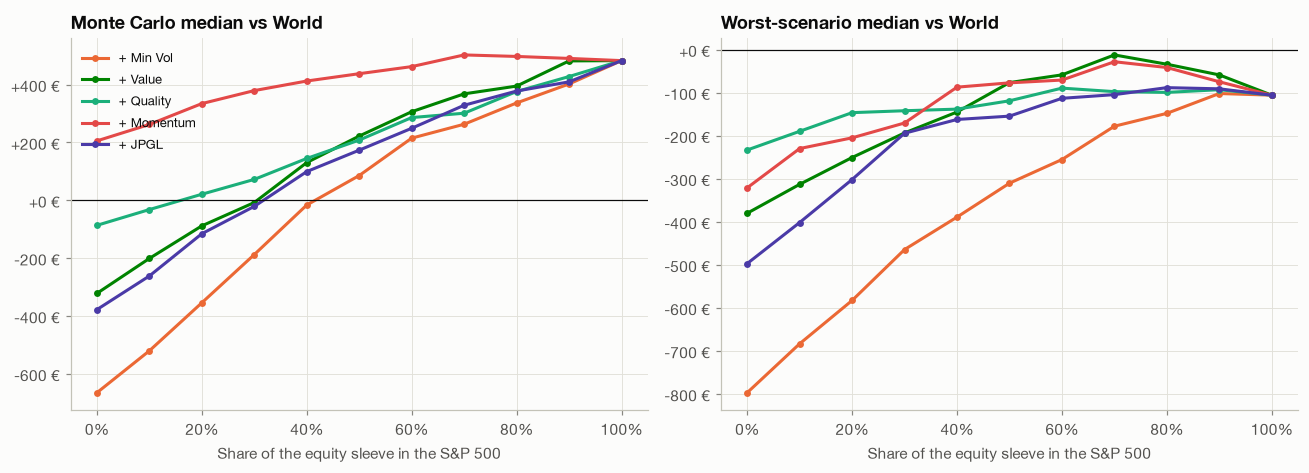

Each pair at the S&P 500 share that does best in the worst scenario:


,,Equity weight (MC),Monte Carlo median vs World €,Worst-scenario median vs World €,CE γ=4 (MC) vs World €
S&P 500 + JPGL,80%,53%,+378 €,-88 €,+329 €
S&P 500 + Min Vol,90%,53%,+402 €,-102 €,+393 €
S&P 500 + Momentum,70%,51%,+502 €,-28 €,+433 €
S&P 500 + Quality,60%,53%,+286 €,-90 €,+277 €
S&P 500 + Value,70%,52%,+368 €,-12 €,+345 €


In [25]:
# blends of the S&P 500 with one other sleeve
PARTNER = {"Min Vol": MV_, "Value": V_, "Quality": Q_, "Momentum": M_, "JPGL": "JPGL"}
BL2 = {}
for lab, k in PARTNER.items():
    for s10 in range(0, 11):
        em = {SP: s10 / 10, k: 1 - s10 / 10} if s10 not in (0, 10) else ({SP: 1} if s10 == 10 else {k: 1})
        sc = score(em)
        if sc:
            BL2[(f"S&P 500 + {lab}", f"{s10 * 10}%")] = sc
BL2 = pd.DataFrame(BL2).T
for c in ["Monte Carlo median €", "Worst-scenario median €", "CE γ=4 (MC) €"]:
    BL2[c.replace(" €", "") + " vs World €"] = BL2[c] - REF_SUB[c]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True)
for (lab, _), c in zip(PARTNER.items(), [SLOT[7], SLOT[3], SLOT[1], SLOT[5], SLOT[4]]):
    sub = BL2.loc[f"S&P 500 + {lab}"]
    xs = [int(i[:-1]) / 100 for i in sub.index]
    axes[0].plot(xs, sub["Monte Carlo median vs World €"], "-o", ms=3.5, color=c, label=f"+ {lab}")
    axes[1].plot(xs, sub["Worst-scenario median vs World €"], "-o", ms=3.5, color=c, label=f"+ {lab}")
for ax, t in zip(axes, ["Monte Carlo median vs World", "Worst-scenario median vs World"]):
    ax.axhline(0, color=INK, lw=0.8); ax.set_title(t); ax.xaxis.set_major_formatter(pct0)
    ax.set_xlabel("Share of the equity sleeve in the S&P 500"); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:+,.0f} €"))
axes[0].legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()
best2 = BL2.loc[BL2.groupby(level=0)["Worst-scenario median vs World €"].idxmax()]
print("Each pair at the S&P 500 share that does best in the worst scenario:")
display(best2[["Equity weight (MC)", "Monte Carlo median vs World €", "Worst-scenario median vs World €", "CE γ=4 (MC) vs World €"]]
        .style.format({"Equity weight (MC)": "{:.0%}", **{c: "{:+,.0f} €" for c in best2 if "vs World" in c}}))

**The full Monte Carlo distribution.** Medians hide the tails. Below, the after-tax outcome at nine percentiles
for the main candidates and the optimiser's picks, each on all 5,000 paths at its own 30%-risk equity weight,
in euros and as the plan's annual money-weighted return (€1,000 + €100 a month, ten years).

In [26]:
def to_mix(lbl):
    return {f: int(v) / 100 for f, v in zip(FAC, lbl.split("/")) if int(v)}
CAND = {"World": {"World": 1}, "S&P 500": {SP: 1},
        "Mom/Qual/Val/MinVol 25/25/25/25": MIX["Mom/Qual/Val/MinVol 25/25/25/25"],
        "Mom/Qual/Val 50/25/25": MIX["Mom/Qual/Val/MinVol 50/25/25/0"],
        "World + Mom + Val, thirds": MIX["World + Mom + Val, thirds"], "JPGL": {"JPGL": 1}}
for c in ["Monte Carlo median", "Worst-scenario median", "CE γ=4 (MC)"]:
    lbl = OPT[c + " vs World €"].idxmax()
    CAND[f"Optimiser ({c}): {lbl}"] = to_mix(lbl)
for lab in best2.index:
    pair, share = lab
    k = PARTNER[pair.replace("S&P 500 + ", "")]
    s_ = int(share[:-1]) / 100
    CAND[f"{pair}, S&P {share}"] = {SP: s_, k: 1 - s_} if 0 < s_ < 1 else ({SP: 1} if s_ == 1 else {k: 1})
CAND = {k: v for k, v in CAND.items() if k == "S&P 500" or v != {SP: 1}}   # drop duplicates of the pure S&P 500

PCT = [1, 5, 10, 25, 50, 75, 90, 95, 99]
P_MC = PATHS[S_MC]
pe, pr, wtab = {}, {}, {}
for nm, em in CAND.items():
    we = weight_for(P_MC, lambda w: wmix(em, w))
    at = run(P_MC, wmix(em, we))[0]["after_tax"]
    pe[nm] = np.percentile(at, PCT)
    pr[nm] = np.percentile(D.irr_annual(at, 1000, 100, H), PCT)
    wtab[nm] = we
cols = [f"p{p}" for p in PCT]
PE = pd.DataFrame(pe, index=cols).T
PR = pd.DataFrame(pr, index=cols).T
PE.insert(0, "Equity weight", pd.Series(wtab))
PR.insert(0, "Equity weight", pd.Series(wtab))
print("Monte Carlo, after tax, € at year 10 (€13,000 paid in); each row at its own 30%-risk equity weight:")
display(PE.style.format({"Equity weight": "{:.0%}", **EUR0(cols)}).background_gradient(cmap="RdYlGn", subset=cols, axis=0))
print("The same, as the plan's annual money-weighted return after tax:")
display(PR.style.format({"Equity weight": "{:.0%}", **{c: "{:+.2%}" for c in cols}}).background_gradient(cmap="RdYlGn", subset=cols, axis=0))

Monte Carlo, after tax, € at year 10 (€13,000 paid in); each row at its own 30%-risk equity weight:


,Equity weight,p1,p5,p10,p25,p50,p75,p90,p95,p99
World,52%,"€11,692","€12,900","€13,640","€14,971","€16,592","€18,438","€20,266","€21,437","€23,943"
S&P 500,52%,"€11,951","€13,090","€13,908","€15,303","€17,098","€19,240","€21,338","€22,741","€25,915"
Mom/Qual/Val/MinVol 25/25/25/25,57%,"€11,557","€12,801","€13,614","€14,959","€16,644","€18,487","€20,283","€21,506","€24,037"
Mom/Qual/Val 50/25/25,52%,"€11,632","€12,947","€13,711","€15,093","€16,778","€18,772","€20,801","€22,137","€25,071"
"World + Mom + Val, thirds",51%,"€11,630","€12,907","€13,722","€15,060","€16,695","€18,663","€20,693","€21,957","€24,882"
JPGL,59%,"€11,291","€12,571","€13,337","€14,630","€16,205","€17,904","€19,546","€20,672","€23,224"
Optimiser (Monte Carlo median): 90/5/5/0,48%,"€11,628","€12,968","€13,687","€15,143","€16,834","€18,944","€21,056","€22,541","€25,564"
Optimiser (Worst-scenario median): 25/60/15/0,55%,"€11,569","€12,893","€13,659","€15,043","€16,704","€18,619","€20,459","€21,669","€24,281"
Optimiser (CE γ=4 (MC)): 100/0/0/0,47%,"€11,617","€12,953","€13,688","€15,132","€16,857","€18,983","€21,073","€22,615","€25,882"
"S&P 500 + JPGL, S&P 80%",53%,"€11,870","€13,025","€13,845","€15,217","€16,947","€19,037","€20,994","€22,273","€25,301"


The same, as the plan's annual money-weighted return after tax:


,Equity weight,p1,p5,p10,p25,p50,p75,p90,p95,p99
World,52%,-2.00%,-0.14%,+0.90%,+2.62%,+4.49%,+6.39%,+8.08%,+9.08%,+11.03%
S&P 500,52%,-1.58%,+0.13%,+1.26%,+3.02%,+5.03%,+7.16%,+9.00%,+10.13%,+12.42%
Mom/Qual/Val/MinVol 25/25/25/25,57%,-2.22%,-0.29%,+0.86%,+2.60%,+4.55%,+6.44%,+8.10%,+9.14%,+11.10%
Mom/Qual/Val 50/25/25,52%,-2.10%,-0.08%,+0.99%,+2.76%,+4.69%,+6.72%,+8.55%,+9.65%,+11.84%
"World + Mom + Val, thirds",51%,-2.10%,-0.13%,+1.01%,+2.72%,+4.60%,+6.61%,+8.45%,+9.51%,+11.71%
JPGL,59%,-2.66%,-0.63%,+0.48%,+2.19%,+4.06%,+5.87%,+7.44%,+8.44%,+10.50%
Optimiser (Monte Carlo median): 90/5/5/0,48%,-2.10%,-0.05%,+0.96%,+2.82%,+4.75%,+6.88%,+8.76%,+9.97%,+12.18%
Optimiser (Worst-scenario median): 25/60/15/0,55%,-2.20%,-0.15%,+0.92%,+2.70%,+4.61%,+6.57%,+8.25%,+9.27%,+11.28%
Optimiser (CE γ=4 (MC)): 100/0/0/0,47%,-2.12%,-0.07%,+0.96%,+2.81%,+4.78%,+6.92%,+8.78%,+10.03%,+12.40%
"S&P 500 + JPGL, S&P 80%",53%,-1.71%,+0.04%,+1.17%,+2.91%,+4.87%,+6.97%,+8.71%,+9.76%,+12.00%


**What the optimiser and the percentiles say.**

- **The "optimal" factor mix depends entirely on what you ask for.** Maximise the Monte Carlo median or the
  risk-averse certainty equivalent and the optimiser goes to **80–100% momentum** (+€216–221 over World on the
  search paths). Maximise the worst-scenario median and it goes to **quality-heavy, 25/60/15/0** — and even then
  ends €145 *below* World: no mix of the four factors beats World if their premia turn out to be just the price
  of their risk. Two objectives, two opposite answers: the inputs cannot tell the factors apart well enough for
  any mix to be optimal in more than one sense.
- **The top is flat.** 58–120 mixes sit within €50 of the best under each objective — less than a tenth of
  the noise in the inputs. The optimiser's precise weights (90/5/5/0, 25/60/15/0) are one draw from a plateau,
  not a target. What survives every objective: **min vol drops out** (≤ 2% in every top-2% average), and
  momentum and quality are the weights that move.
- **Momentum-only is the CE winner, but look at what it buys.** 100% momentum carries only 47% equity at the 30%
  risk level, because it is the most volatile sleeve; its percentiles beat World from p5 up (+€53 at p5, +€265 at
  p50, +€1,940 at p99) — the gain is in the good half of the distribution, and it rests on one premium and one fund.
- **The S&P 500 blends are the strongest rows, for the S&P 500's reason.** Every S&P blend beats World at every
  percentile above p5, by +€280–500 at the median, and S&P + value at 70/30 has the best p5 of all (€13,161).
  Mixing in a second sleeve narrows the worst-scenario shortfall to −€12 (value) and −€28 (momentum) against
  −€88 to −€102 for JPGL and min vol, which drag more than they protect. But these are all
  mostly-S&P-500 portfolios: they inherit its premise (US leadership continues, §6), and the partner sleeve is a
  modest diversifier, not a hedge.
- **The tails are close everywhere.** Between the best and worst row the p1 differs by €660 and the p5 by €590;
  the p99 by €2,700. The choice of equity sleeve mostly moves the *upside*; the downside is fixed by the 30% risk
  level — which is the point of dialling every row to it.

### 7c · Sectors and regions

Two measures. **What each fund holds today** (sector weights as reported for each fund; country weights from
the issuers via justETF, 2026-08-31). And **how each behaved** — a returns-based fit of each index on the ten
MSCI World sector indexes and on four regions (USA, Europe, Japan, Pacific ex Japan), which shows the
exposure it actually carried over 2014–2026 rather than on one date.

**The rules behind the factor indexes.** MSCI Minimum Volatility keeps each sector and each large country
within ±5 points of MSCI World. Quality is *Sector Neutral* (sector weights match World by construction).
Enhanced Value is sector-relative in how it scores stocks. Momentum has no sector constraint and follows
whatever has been rising — today, technology. JPGL's index starts from equal *risk* across regional
industries (inverse volatility of each region's industry groups), then scales each region back to its market
weight — so it is region-aware but sector-diversifying.

In [27]:
SEC_T = {"World": "EUNL.DE", SP: "SXR8.DE", M_: "IS3R.DE", Q_: "IS3Q.DE", V_: "IS3S.DE", MV_: "IQQ0.DE", "JPGL": "JPGL.DE"}
SW = pd.DataFrame({k: pf.yahoo_sector_weights(t) for k, t in SEC_T.items()})
SW.index = SW.index.str.replace("_", " ").str.capitalize()
OPTS = {"World": {"World": 1}, SP: {SP: 1}, **{FLAB[f]: {f: 1} for f in FAC},
        "4 × 25% blend": {f: .25 for f in FAC}, "Thirds without Min Vol": {M_: 1/3, Q_: 1/3, V_: 1/3},
        "Mom/Qual/Val 50/25/25": {M_: .5, Q_: .25, V_: .25}, "World + Mom + Val": {"World": 1/3, M_: 1/3, V_: 1/3},
        "Mom + Qual + Val + JPGL": {M_: .25, Q_: .25, V_: .25, "JPGL": .25}, "JPGL": {"JPGL": 1}}
SO = pd.DataFrame({o: sum(SW[k] * v for k, v in m.items()) for o, m in OPTS.items()})
SO = SO.loc[SO["World"].sort_values(ascending=False).index]
SO.loc["Largest sector"] = SO.max()
SO.loc["Effective number of sectors"] = 1 / (SO.iloc[:-1] ** 2).sum()
display(SO.style.format("{:.0%}").format("{:.1f}", subset=pd.IndexSlice[["Effective number of sectors"], :])
        .background_gradient(cmap="Oranges", subset=pd.IndexSlice[SO.index[:-2], :], vmin=0, vmax=0.35, axis=None))
US = {"World": 0.703, SP: 1.0, M_: 0.574, Q_: 0.698, V_: 0.462, MV_: 0.634, "JPGL": 0.575}
print("Share in US companies (issuer data, 2026-08-31): " + ", ".join(f"{o} {sum(US[k] * v for k, v in m.items()):.0%}" for o, m in OPTS.items()))
print("Effective number of sectors = 1 / Σ weight²: 11 if all eleven were equal, 1 if everything were in one.")

,World,S&P 500,Momentum,Quality,Value,Min Vol,4 × 25% blend,Thirds without Min Vol,Mom/Qual/Val 50/25/25,World + Mom + Val,Mom + Qual + Val + JPGL,JPGL
Technology,30%,40%,40%,33%,34%,24%,33%,36%,37%,35%,29%,9%
Financial services,16%,11%,16%,15%,15%,14%,15%,15%,15%,16%,14%,12%
Industrials,11%,8%,11%,10%,11%,9%,10%,11%,11%,11%,11%,10%
Healthcare,9%,9%,8%,9%,8%,14%,10%,9%,8%,9%,10%,14%
Consumer cyclical,9%,9%,2%,8%,8%,5%,6%,6%,5%,6%,7%,8%
Communication services,8%,10%,6%,9%,8%,10%,8%,8%,7%,7%,7%,5%
Consumer defensive,5%,4%,2%,5%,4%,10%,5%,4%,3%,4%,5%,9%
Energy,4%,3%,10%,4%,4%,5%,6%,6%,7%,6%,7%,8%
Basic materials,3%,2%,3%,3%,3%,0%,2%,3%,3%,3%,4%,8%
Utilities,2%,2%,2%,2%,2%,7%,3%,2%,2%,2%,4%,9%


Share in US companies (issuer data, 2026-08-31): World 70%, S&P 500 100%, Momentum 57%, Quality 70%, Value 46%, Min Vol 63%, 4 × 25% blend 59%, Thirds without Min Vol 58%, Mom/Qual/Val 50/25/25 58%, World + Mom + Val 58%, Mom + Qual + Val + JPGL 58%, JPGL 57%
Effective number of sectors = 1 / Σ weight²: 11 if all eleven were equal, 1 if everything were in one.


In [28]:
sec = D.sector_indexes().loc[:END]
reg = eq[["USA", "Europe", "Japan", "Pacific ex Japan"]]
def fit(y, Xd, start="2014-12"):
    x_ = pd.concat([y.rename("y"), Xd], axis=1).loc[start:END].dropna()
    A_, b_ = x_[Xd.columns].to_numpy(), x_["y"].to_numpy()
    w_ = optimize.minimize(lambda w: ((b_ - A_ @ w) ** 2).sum(), np.full(A_.shape[1], 1 / A_.shape[1]), bounds=[(0, 1)] * A_.shape[1],
                           constraints=({"type": "eq", "fun": lambda w: w.sum() - 1},)).x
    return pd.Series(np.r_[w_, 1 - (b_ - A_ @ w_).var() / b_.var()], index=list(Xd.columns) + ["R² of the fit"])
GR = {"World": eq["World"], SP: eq[SP], **{FLAB[f]: eq[f] for f in FAC}, "4 × 25% blend": eq[FAC].mean(axis=1),
      "Thirds without Min Vol": eq[[M_, Q_, V_]].mean(axis=1), "Mom/Qual/Val 50/25/25": 0.5 * eq[M_] + 0.25 * eq[Q_] + 0.25 * eq[V_]}
RB = pd.DataFrame({k: fit(v, reg) for k, v in GR.items()})
RB["JPGL (own record, 2019-11 →)"] = fit(jp, reg, "2019-11")
print("Regional exposure the returns imply, 2014-12 → 2026-09:")
display(RB.style.format("{:.0%}"))
SB = pd.DataFrame({k: fit(GR[k], sec) for k in ["World", SP] + [FLAB[f] for f in FAC]
                   + ["4 × 25% blend", "Thirds without Min Vol", "Mom/Qual/Val 50/25/25"]})
SB["JPGL (own record, 2019-11 →)"] = fit(jp, sec, "2019-11")
print("Sector exposure the returns imply, 2014-12 → 2026-09 (what the mix behaved like, not what it holds today):")
display(SB.style.format("{:.0%}").background_gradient(cmap="Oranges", subset=pd.IndexSlice[SB.index[:-1], :], vmin=0, vmax=0.35, axis=None))

Regional exposure the returns imply, 2014-12 → 2026-09:


,World,S&P 500,Momentum,Quality,Value,Min Vol,4 × 25% blend,Thirds without Min Vol,Mom/Qual/Val 50/25/25,"JPGL (own record, 2019-11 →)"
USA,69%,95%,82%,69%,20%,41%,54%,57%,63%,37%
Europe,20%,3%,5%,26%,42%,28%,26%,25%,20%,33%
Japan,7%,1%,13%,5%,36%,20%,19%,18%,17%,9%
Pacific ex Japan,4%,1%,0%,0%,2%,10%,1%,0%,0%,20%
R² of the fit,100%,99%,76%,96%,83%,43%,94%,95%,92%,85%


Sector exposure the returns imply, 2014-12 → 2026-09 (what the mix behaved like, not what it holds today):


,World,S&P 500,Momentum,Quality,Value,Min Vol,4 × 25% blend,Thirds without Min Vol,Mom/Qual/Val 50/25/25,"JPGL (own record, 2019-11 →)"
Energy,4%,5%,0%,2%,7%,4%,2%,2%,0%,7%
Materials,4%,0%,0%,2%,23%,0%,4%,5%,2%,10%
Industrials,11%,6%,24%,19%,5%,0%,14%,20%,23%,18%
Cons Discretionary,11%,14%,0%,6%,0%,6%,0%,0%,0%,7%
Cons Staples,6%,3%,0%,13%,4%,34%,13%,6%,3%,10%
Health Care,13%,17%,27%,18%,8%,29%,21%,19%,22%,22%
Financials,15%,11%,0%,8%,34%,2%,13%,15%,12%,13%
Info Technology,23%,30%,36%,23%,17%,2%,20%,25%,27%,2%
Comm Services,9%,8%,8%,7%,2%,2%,6%,6%,7%,0%
Utilities,4%,4%,5%,2%,0%,21%,7%,2%,3%,11%


**Does diversification protect in a crisis?** Test it directly: an **equal-sector** World (each of the ten
sectors at 10%) and an **equal-region** World (four regions at 25%), against World, the factor mixes and
min vol, 2001–2026, index level.

In [29]:
DV = pd.DataFrame({"World": eq["World"], SP: eq[SP], "Equal-sector World (10 × 10%)": sec.mean(axis=1, skipna=False),
                   "Equal-region World (4 × 25%)": reg.mean(axis=1, skipna=False), "4 × 25% factor blend": eq[FAC].mean(axis=1),
                   "Thirds without Min Vol": eq[[M_, Q_, V_]].mean(axis=1),
                   "Mom/Qual/Val 50/25/25": 0.5 * eq[M_] + 0.25 * eq[Q_] + 0.25 * eq[V_],
                   "World + Mom + Val": (eq["World"] + eq[M_] + eq[V_]) / 3,
                   "Mom + Qual + Val + JPGL": pd.concat([eq[[M_, Q_, V_]], pf.splice(jg, gross[STY] @ w_sty)], axis=1).mean(axis=1, skipna=False),
                   "Min Vol": eq[MV_]}).loc["2001-01":END].dropna()
rows = {}
for c in DV:
    ct = D.crisis_table(DV[[c]])[c]
    rows[c] = {"CAGR": pf.perf_stats(DV[c])["CAGR"], "Volatility": DV[c].std() * np.sqrt(12),
               "Down capture vs World": D.capture_ratios(DV[c], DV["World"])["Down capture"],
               **{k: ct[k] for k in ["GFC 2007-09", "Euro crisis 2011", "COVID 2020", "Inflation 2022"]}}
DVT = pd.DataFrame(rows).T
display(DVT.style.format(P1([c for c in DVT if c != "Down capture vs World"]) | {"Down capture vs World": "{:.2f}"})
        .background_gradient(cmap="RdYlGn", subset=["GFC 2007-09", "Euro crisis 2011", "COVID 2020", "Inflation 2022"], vmin=-0.5, vmax=0.05)
        .background_gradient(cmap="RdYlGn_r", subset=["Down capture vs World"], vmin=0.5, vmax=1))
print("Down capture = average fall in months World fell, as a share of World's fall (below 1 = falls less).")

,CAGR,Volatility,Down capture vs World,GFC 2007-09,Euro crisis 2011,COVID 2020,Inflation 2022
World,6.7%,13.9%,1.00,-47.6%,-11.1%,-19.8%,-13.4%
S&P 500,7.6%,14.8%,1.02,-44.5%,-8.1%,-19.0%,-11.9%
Equal-sector World (10 × 10%),6.9%,13.0%,0.90,-43.4%,-9.3%,-20.7%,-8.0%
Equal-region World (4 × 25%),6.3%,13.3%,0.93,-48.1%,-10.0%,-20.3%,-12.6%
4 × 25% factor blend,7.9%,12.3%,0.83,-44.7%,-6.4%,-18.4%,-11.5%
Thirds without Min Vol,8.5%,13.4%,0.92,-47.5%,-10.0%,-19.0%,-13.7%
Mom/Qual/Val 50/25/25,8.7%,13.4%,0.90,-47.1%,-8.5%,-18.2%,-14.1%
World + Mom + Val,8.3%,13.7%,0.94,-48.7%,-11.0%,-19.7%,-12.9%
Mom + Qual + Val + JPGL,8.2%,13.0%,0.89,-46.4%,-8.8%,-19.7%,-12.0%
Min Vol,5.9%,10.6%,0.57,-35.6%,4.6%,-16.4%,-4.8%


Down capture = average fall in months World fell, as a share of World's fall (below 1 = falls less).


### 7d · What this means

All figures at the 30% bad-case drawdown, after fund cost, the €1 orders, stamp duty and Italian tax. Annual
returns are the plan's money-weighted return on €1,000 + €100 a month.

**The candidates side by side**

| | **World** | S&P 500 | Mom/Qual/Val 50/25/25 | 4 × 25% (with min vol) | Mom/Qual/Val thirds | World + Mom + Val thirds |
|---|---|---|---|---|---|---|
| Equity weight at the risk level | 52% | 52% | 52% | 57% | 53% | 51% |
| Monte Carlo median | €16,592 · 4.49% | **€17,098 · 5.03%** | €16,778 · 4.69% | €16,644 · 4.55% | €16,734 · 4.65% | €16,695 · 4.60% |
| Worst-scenario median | **€16,553 · 4.45%** | €16,548 · 4.44% | €16,470 · 4.36% | €16,381 · 4.26% | €16,488 · 4.38% | €16,523 · 4.41% |
| Ahead of World (Monte Carlo paths) | — | **77%** | 62% | 50% | 57% | 57% |
| History, all 213 windows: median / worst | 5.74% / −1.00% | **6.88%** / −1.53% | 5.94% / **+0.26%** | 5.69% / −0.12% | 5.82% / +0.21% | 5.61% / +0.18% |
| History, 23 live windows: median · ahead of World | 5.73% · — | **6.81% · 100%** | 5.57% · 52% | 5.16% · 22% | 5.35% · 30% | 5.30% · 30% |
| Live alpha vs World /yr (t) · per unit of residual risk | — | +1.5% (2.1) · **0.58** | +1.7% (1.8) · 0.41 | +1.0% (1.3) · 0.35 | +1.2% (1.3) · 0.35 | +1.1% (1.2) · 0.33 |
| Down capture vs World · 2022 (calendar) | 1.00 · −12.7% | 1.02 · −13.3% | 0.90 · −10.6% | **0.83 · −8.5%** | 0.92 · −10.1% | 0.94 · −9.6% |
| Technology today · effective sectors · US | 30% · 6.2 · 70% | 40% · 4.7 · 100% | 37% · 5.1 · 58% | 33% · 5.9 · 59% | 36% · 5.3 · 58% | 35% · 5.5 · 58% |

**(a) One fund or four.** No ETF holds an MSCI factor blend. The single-fund multifactor ETFs each use their own
recipe, and the two with a long record (HSBC, iShares) delivered about World's return with alpha t-stats
under 1; HSBC distributes, iShares changed index in 2025, Invesco and Avantis are active and too new to judge.
The tax a single fund would save by netting factor losses is €0 at the median and €62 at the 95th percentile,
and on Trade Republic Italy a stranded ETF loss still offsets gains on shares, ETCs or certificates for four
years. **Separate savings plans remain the way to own a blend** — three or four of them, not one fund.

**(b) Which mix.** Measured against MSCI World, only momentum's live alpha survives the shrinkage in any size
(+1.35%/yr expected); quality, value and min vol contribute +0.3% or less. That orders everything:

- **No mix beats World on robustness.** Every mix's worst-scenario median is at or below World's €16,553 — if
  lower risk is simply paid for with lower return, every tilt ends level or behind (the S&P 500 −€5, World +
  momentum + value −€30, the 4 × 25% blend −€170, pure min vol −€730).
- **The S&P 500 tops every expected-return view** — see §6 for why that is a bet on the US decade repeating,
  not a free improvement: it also has the worst real 10-year window of these six and no regional diversification.
- **Among factor mixes, the more momentum, the higher the Monte Carlo median.** The top factor rows are 75–100%
  momentum (+€235–265 over World), then the momentum-heavy blends; 50/25/25 is +€186, ahead on 62% of paths. This
  is one premium carrying the ranking, and the factor most exposed to sharp reversals.
- **History agrees on momentum and adds quality.** Mixes of only momentum and quality top the factor mixes in
  both the full and the live history (50/50: 6.29%/yr against World's 5.74%, ahead of World in every live
  window). Among the factor candidates above, 50/25/25 has the best full-history median and worst window
  (+0.26%/yr against −1.00%), but 75/0/25/0 and 100/0/0/0 had better worst windows still (+0.7%).
- **What a momentum tilt costs.** Concentration: 50/25/25 holds 37% technology and about five effective
  sectors. Its beta is close to 1, so it does little in a broad crash (GFC −47%, like World).
- **The 4 × 25% blend is the defensive variant.** It has the best crash record (down capture 0.83, 2022
  −8.5%, GFC −45%), but the Monte Carlo puts it level with World (−€6 at the median, ahead on half the paths)
  and it gave up most in the live decade (ahead in 22% of windows): min vol is insurance, and the last decade
  did not need it.
- **History and the Monte Carlo agree on the range, not on the winner.** Every historical result falls inside
  the Monte Carlo's 5th–95th band; the full record was a lucky draw for factors (≈ 73rd–79th percentile) and
  the live decade an unlucky one (≈ 25th–39th).
- **Value earns its place as a diversifier, not a return source.** Its live alpha is nil, but it holds the
  regional tilt (Europe, Japan) and is one of momentum's two least correlated partners (0.74; min vol 0.71).
  Mixes heavy in value move least between scenarios (spreads of €60–90).

**(c) Sectors and regions.**
- **Factor by factor, today's holdings.** Momentum is the most concentrated sleeve (40% technology, 10% energy,
  4.5 effective sectors — it holds whatever has risen); quality and value sit close to World (33–34% technology);
  min vol is the only one that diversifies sectors (24% technology, 7.4 effective sectors, heavy in health care,
  staples and utilities). The S&P 500 is as concentrated as momentum (40% technology, 4.7 effective sectors).
- **The factor mixes diversify by region, not by sector.** All hold about 58–59% US against World's 70% (value
  46%, momentum 57%), with more Japan (17% implied for 50/25/25, against 7%; value 36%); none but min vol
  diversifies sectors — the momentum-heavy ones hold more technology than World.
- **Sector diversification protects in sector-led crashes, beta reduction in broad ones.** The equal-sector
  World fell less in the GFC (financials) and 2022 (technology) but more in COVID; min vol and the 4 × 25%
  blend cushioned more across all falling months. If a technology-led crash is the risk you most want covered,
  replacing min vol with JPGL (momentum + quality + value + JPGL, 25% each: largest sector 29%) is the
  sector-diversified variant, at about World's Monte Carlo median (+€67) and €120 below 50/25/25.

**The decision**

| If you want… | Choose | Monthly €100 |
|---|---|---|
| The robust choice: no bet that depends on a scenario | **World + euro govt 7-10** (equity 52%) | €52 World (UETW), €48 bonds (X710) |
| A bet that the US keeps leading | S&P 500 + euro govt 7-10 (equity 52%) | €52 S&P 500 (SPYL), €48 bonds |
| A tilt to the one factor premium that held up live | Mom/Qual/Val 50/25/25 + euro govt 7-10 (equity 52%) | €26 momentum (XDEM), €13 quality (IS3Q), €13 value (IS3S), €48 bonds |
| The S&P 500 with a diversifier (§7b-bis) | 70% S&P 500 + 30% value + euro govt 7-10 (equity 52%) | €36 S&P 500 (SPYL), €16 value (IS3S), €48 bonds |
| The smoothest ride in a broad crash | 4 × 25% + euro govt 7-10 (equity 57%) | €14 each factor (+ min vol, XDEB), €43 bonds |
| Less technology than World | Mom + Qual + Val + JPGL + euro govt 7-10 (equity 55%) | €14 each, €45 bonds |

**Whichever you choose, the differences are small** — €0–500 over ten years at the median, at most 0.5
points a year — against Monte Carlo spreads of about −€1,000 to +€2,200 versus World. The bigger decision was
the risk level; this one is a tilt. Choose a tilt only if you will keep it through the years it trails World:
even the strongest candidate trails on almost a quarter of the simulated paths.

## 8 · The bond sleeve revisited

Is euro government 7-10 the right bond sleeve, or is it too concentrated in one curve and too exposed to
rates? `portfolio_choice` §4 chose it next to World; here the question is re-asked next to the
**Mom/Qual/Val 50/25/25** tilt (§7d) as well as World, over the same 10 years and the same 30% risk level, with more candidates:

- **Euro-area government ladders** of every middle maturity: 1-3, 1-10, 3-7, 5-7, 3-10, 5-10, 7-10 (all issuers,
  rebuilt from the ECB par curve from 2004-10 and from German Bunds before, as in §2), and a **barbell** of 1-3 and 7-10.
- **US Treasuries hedged to EUR** (all maturities, duration ≈ 5.5) — a second central bank and the classic crash
  hedge — alone and 50/50 with euro 7-10.
- **Cash** (an €STR fund), as the zero-duration end.

Bonds earn today's yield less the fund fee (§3); hedged Treasuries also carry the 0.35% extra hedging cost
measured in `portfolio_choice` §4, and today's hedge carry is €STR − SOFR (the two overnight rates forward
points track). Their history is hedged at the 3-month interbank differential on both sides, so the carry
compares like with like (a T-bill against Euribor would add the US bank-credit spread — 1.4%/yr through
2007-09 — exactly in the crisis the hedge is judged on). The rebuilt ladders now include the **roll-down**
each bond earns as it ages along the curve. In the Monte Carlo every bond sleeve shares **one** ± 0.5-point
draw per path, since a surprise in euro rates moves all maturities together; cash takes twice that draw
(± 1 point), because a fund rolling one-month money takes every move in policy rates in full.

In [30]:
ea_c, bund_c = D.ea_curve(END), D.bund_curve()
eqw = lambda ms: {m: 1 / len(ms) for m in ms}
LAD8 = {"1-3": [1, 2, 3], "1-10": [1, 2, 3, 5, 7, 10], "3-7": [3, 5, 7], "5-7": [5, 7], "3-10": [3, 5, 7, 10],
        "5-10": [5, 7, 10], "7-10": [7, 10]}
FEE8 = {k: 0.0010 if k == "1-3" else 0.0015 for k in LAD8}
B8 = pd.DataFrame({f"Euro govt {k}": D.net_of_cost(pf.splice(pf.ladder_return({m: ea_c[m] for m in ms}, eqw(ms), full_curve=ea_c).dropna(),
                                                             pf.ladder_return({m: bund_c[m] for m in ms}, eqw(ms), full_curve=bund_c).dropna()), FEE8[k])
                   for k, ms in LAD8.items()})
B8["UST hedged"] = D.net_of_cost(bonds["US Treasury (EUR hedged)"], 0.0008 + 0.0035)
B8["Cash (€STR fund)"] = RF.reindex(B8.index).ffill() - 0.0010 / 12
EQ8 = {"World": {"World": 1}, "Mom/Qual/Val 50/25/25": {FAC[0]: .5, FAC[1]: .25, FAC[2]: .25}}
X8 = pd.concat([H_[["World"] + FAC[:3]], B8], axis=1).loc["1999-02":END].dropna()
print(f"Joint sample {X8.index[0]:%Y-%m} → {X8.index[-1]:%Y-%m} ({len(X8)} months); "
      f"euro 7-10 here vs §2's series: correlation {X8['Euro govt 7-10'].corr(H_['EUR Govt 7-10'].reindex(X8.index)):.4f}")

# today's yields, durations and roll-down
CUR8 = {m: float(s.loc[:END].dropna().iloc[-1]) for m, s in ea_c.items()}
ust_c = D.ust_curve(END)
UCUR = {m: float(s.loc[:END].dropna().iloc[-1]) for m, s in ust_c.items()}
YL8 = D.current_yields(END)
mdur = lambda cv, w: sum(v * (1 - (1 + cv[m]) ** -m) / cv[m] for m, v in w.items())
BINFO = {f"Euro govt {k}": {"Duration": mdur(CUR8, eqw(ms)), "Yield after fee": np.mean([CUR8[m] for m in ms]) - FEE8[k],
                            "Roll-down if the curve stays put": D.rolldown(CUR8, eqw(ms))} for k, ms in LAD8.items()}
BINFO["UST hedged"] = {"Duration": mdur(UCUR, D.US_ALL_WEIGHTS),
                       "Yield after fee": YL8.loc["All maturities", "US Treasury, EUR hedged"] - 0.0008 - 0.0035,
                       "Roll-down if the curve stays put": D.rolldown(UCUR, D.US_ALL_WEIGHTS)}
BINFO["Cash (€STR fund)"] = {"Duration": 0.0, "Yield after fee": float(RF.loc[:END].dropna().iloc[-1] * 12) - 0.0010,
                             "Roll-down if the curve stays put": 0.0}
BINFO = pd.DataFrame(BINFO).T
cs = D.crisis_table(X8[list(B8)])
hist8 = pd.DataFrame({"CAGR 1999–2026": X8[list(B8)].apply(lambda s: pf.perf_stats(s)["CAGR"]),
                      "Max drawdown": X8[list(B8)].apply(lambda s: pf.perf_stats(s)["Max drawdown"]),
                      "Correlation with World": X8[list(B8)].corrwith(X8["World"]),
                      "…since 2022": X8.loc["2022":, list(B8)].corrwith(X8.loc["2022":, "World"]),
                      "GFC 2007-09": cs.loc["GFC 2007-09"], "COVID 2020": cs.loc["COVID 2020"], "Inflation 2022": cs.loc["Inflation 2022"]})
BI = BINFO.join(hist8)
display(BI.style.format({"Duration": "{:.1f}", **{c: "{:.2%}" for c in ["Yield after fee", "Roll-down if the curve stays put"]},
                         **{c: "{:+.2f}" for c in ["Correlation with World", "…since 2022"]},
                         **{c: "{:.1%}" for c in ["CAGR 1999–2026", "Max drawdown", "GFC 2007-09", "COVID 2020", "Inflation 2022"]}})
        .background_gradient(cmap="RdYlGn", subset=["GFC 2007-09", "COVID 2020", "Inflation 2022"], vmin=-0.25, vmax=0.25))
_lad = BI.loc[[f"Euro govt {k}" for k in LAD8]]
_slope = np.polyfit(_lad["Duration"], _lad["Yield after fee"], 1)[0]
_shock = np.polyfit(_lad["Duration"], _lad["Inflation 2022"], 1)[0]
print(f"Each year of duration adds ≈ {_slope:.2%} of yield on today's euro curve ({CUR8[1]:.1%} at 1 year, {CUR8[10]:.1%} at 10) and ≈ {-_shock:.1%}")
print("of loss in a 2022-style rate shock. Hedged Treasuries cushion crashes best but yield less after the hedge.")

Joint sample 1999-02 → 2026-09 (332 months); euro 7-10 here vs §2's series: correlation 1.0000


,Duration,Yield after fee,Roll-down if the curve stays put,CAGR 1999–2026,Max drawdown,Correlation with World,…since 2022,GFC 2007-09,COVID 2020,Inflation 2022
Euro govt 1-3,1.9,3.16%,0.35%,2.0%,-6.5%,-0.13,+0.45,9.1%,-0.5%,-4.4%
Euro govt 1-10,4.1,3.40%,0.46%,2.6%,-13.4%,-0.03,+0.57,9.5%,-1.5%,-10.1%
Euro govt 3-7,4.4,3.47%,0.46%,2.8%,-14.6%,-0.05,+0.55,10.4%,-1.5%,-11.0%
Euro govt 5-7,5.3,3.57%,0.52%,3.1%,-17.2%,-0.03,+0.57,10.4%,-1.8%,-13.1%
Euro govt 3-10,5.4,3.58%,0.51%,3.0%,-17.6%,-0.01,+0.59,10.0%,-2.0%,-13.4%
Euro govt 5-10,6.2,3.69%,0.57%,3.2%,-20.2%,+0.00,+0.60,10.0%,-2.4%,-15.6%
Euro govt 7-10,7.1,3.79%,0.62%,3.4%,-22.9%,+0.02,+0.62,9.6%,-3.0%,-17.8%
UST hedged,5.5,3.24%,0.33%,2.3%,-22.7%,-0.27,+0.37,16.5%,5.7%,-14.1%
Cash (€STR fund),0.0,2.31%,0.00%,1.5%,-3.6%,-0.16,+0.22,5.3%,-0.1%,-0.3%


Each year of duration adds ≈ 0.12% of yield on today's euro curve (3.1% at 1 year, 4.1% at 10) and ≈ 2.6%
of loss in a 2022-style rate shock. Hedged Treasuries cushion crashes best but yield less after the hedge.


### 8a · Every bond sleeve at the same risk

Each bond sleeve is paired with each equity sleeve and the equity weight dialled to the **30% bad-case
drawdown**, as in §4. Roll-down (the extra return of a constant-maturity fund while the curve stays as steep
as today) is left out of the base case and added in the second panel: it favours the longer sleeves.

In [31]:
BO8 = {**{f"Euro govt {k}": {f"Euro govt {k}": 1} for k in LAD8},
       "Barbell: euro 1-3 + 7-10": {"Euro govt 1-3": .5, "Euro govt 7-10": .5},
       "Euro 7-10 + UST hedged, 50/50": {"Euro govt 7-10": .5, "UST hedged": .5},
       "UST hedged": {"UST hedged": 1}, "Cash (€STR fund)": {"Cash (€STR fund)": 1}}
COLS8 = list(X8.columns)
EQ8C = ["World"] + FAC[:3]
TAX8 = np.array([0.125 if (c.startswith("Euro") or c.startswith("UST")) else 0.26 for c in COLS8])
BT8 = BINFO["Yield after fee"].to_dict()
MU8 = {**{k: MC_MU[k] for k in EQ8C}, **BT8}

def mc8(mu, seed=41):
    P = D.bootstrap_on_targets(X8, H, N, 12, seed=seed, targets=mu)
    rng = np.random.default_rng(seed + 1000)
    mkt, bnd = rng.normal(0, MC_SD_MKT, N), rng.normal(0, MC_SD_BOND, N)
    z = pd.DataFrame(rng.standard_normal((N, len(ACORR))) @ ACHOL.T, columns=ACORR.index)
    for i, c in enumerate(COLS8):
        # cash follows the same rate surprise, doubled: a fund rolling 1-month money takes every move in
        # policy rates in full, where a 10-year bond return is anchored by its starting yield
        d = (BETA[c] * mkt + (ASE[c] * z[c].to_numpy() if c in z else 0.0)) if c in EQ8C else (2 * bnd if c.startswith("Cash") else bnd)
        P[..., i] = (1 + P[..., i]) * np.exp((np.log1p(mu[c] + d) - np.log1p(mu[c])) / 12)[:, None] - 1
    return P

WF8 = np.round(np.arange(0.30, 0.801, 0.025), 3)
run8 = lambda P, wv: (lambda r: (r, D.outcome_summary(r, H)))(D.pac_paths_rule(P, wv, TAX8, "split"))
def w8(em, bm, we):
    d = {**{k: we * v for k, v in em.items()}, **{k: (1 - we) * v for k, v in bm.items()}}
    return np.array([d.get(c, 0.0) for c in COLS8])

rows, AT8 = {}, {}
VAR8 = {"Yield only": MU8, "Yield + roll-down": {**MU8, **{k: BT8[k] + BINFO.loc[k, "Roll-down if the curve stays put"] for k in BT8}}}
for v, mu in VAR8.items():
    P = mc8(mu)
    for e, em in EQ8.items():
        for b, bm in BO8.items():
            outs = [run8(P, w8(em, bm, w)) for w in WF8]
            dd, wg = rising([-o["p5 max DD"] for _, o in outs], WF8)
            we = float(np.interp(RISK_T, dd, wg))
            res, o = run8(P, w8(em, bm, we))
            AT8[(v, e, b)] = res["after_tax"]
            rows[(v, e, b)] = {"Equity weight": we, "Median €": o["Median €"], "Median %/yr": o["Median IRR"],
                               "Bad case p5 €": o["Bad case p5 €"]}
R8 = pd.DataFrame(rows).T
for (v, e) in itertools.product(VAR8, EQ8):
    ref = AT8[(v, e, "Euro govt 7-10")]
    for b in BO8:
        R8.loc[(v, e, b), "vs euro 7-10 €"] = R8.loc[(v, e, b), "Median €"] - R8.loc[(v, e, "Euro govt 7-10"), "Median €"]
        R8.loc[(v, e, b), "Beats euro 7-10 (paths)"] = (AT8[(v, e, b)] > ref).mean() if b != "Euro govt 7-10" else np.nan
port = lambda e, b, we: sum(we * x * X8[k] for k, x in EQ8[e].items()) + sum((1 - we) * x * X8[k] for k, x in BO8[b].items())
for b in BO8:
    we = R8.loc[("Yield only", "Mom/Qual/Val 50/25/25", b), "Equity weight"]
    ct = D.crisis_table(port("Mom/Qual/Val 50/25/25", b, we).to_frame("x"))["x"]
    for c in ["GFC 2007-09", "COVID 2020", "Inflation 2022"]:
        R8.loc[("Yield only", "Mom/Qual/Val 50/25/25", b), f"Portfolio, {c}"] = ct[c]

MAIN8 = R8.loc[("Yield only", "Mom/Qual/Val 50/25/25")].copy()
MAIN8.insert(0, "Duration", [BINFO["Duration"].get(b, np.nan) if b in BINFO.index else
                             sum(x * BINFO.loc[k, "Duration"] for k, x in BO8[b].items()) for b in MAIN8.index])
MAIN8["With roll-down: vs euro 7-10 €"] = R8.loc[("Yield + roll-down", "Mom/Qual/Val 50/25/25"), "vs euro 7-10 €"]
MAIN8["With World as equity: vs euro 7-10 €"] = R8.loc[("Yield only", "World"), "vs euro 7-10 €"]
MAIN8 = MAIN8.sort_values("Median €", ascending=False)
print("Mom/Qual/Val 50/25/25 + each bond sleeve, every row at a 30% bad-case drawdown (Monte Carlo, after tax):")
display(MAIN8.style.format({"Duration": "{:.1f}", "Equity weight": "{:.0%}", "Median %/yr": "{:.2%}", "Beats euro 7-10 (paths)": "{:.0%}",
                            **EUR0(["Median €", "Bad case p5 €"]), **{c: "{:+,.0f} €" for c in MAIN8 if "vs euro" in c},
                            **{c: "{:.1%}" for c in MAIN8 if c.startswith("Portfolio")}}, na_rep="—")
        .background_gradient(cmap="Greens", subset=["Median €"])
        .background_gradient(cmap="RdYlGn", subset=[c for c in MAIN8 if c.startswith("Portfolio")], vmin=-0.3, vmax=0))
print("Portfolio, … = the whole portfolio at that equity weight through each real crisis (history, rebalanced monthly).")

Mom/Qual/Val 50/25/25 + each bond sleeve, every row at a 30% bad-case drawdown (Monte Carlo, after tax):


,Duration,Equity weight,Median €,Median %/yr,Bad case p5 €,vs euro 7-10 €,Beats euro 7-10 (paths),"Portfolio, GFC 2007-09","Portfolio, COVID 2020","Portfolio, Inflation 2022",With roll-down: vs euro 7-10 €,With World as equity: vs euro 7-10 €
Euro govt 7-10,7.1,52%,"€16,784",4.70%,"€12,945",+0 €,—,-24.2%,-11.1%,-15.8%,+0 €,+0 €
"Euro 7-10 + UST hedged, 50/50",6.3,55%,"€16,744",4.66%,"€13,029",-40 €,50%,-24.6%,-9.6%,-14.8%,-111 €,-50 €
Euro govt 5-10,6.2,53%,"€16,717",4.63%,"€13,009",-67 €,41%,-24.4%,-10.9%,-14.7%,-91 €,-45 €
UST hedged,5.5,57%,"€16,680",4.59%,"€13,018",-104 €,49%,-24.5%,-8.2%,-14.0%,-237 €,-125 €
Euro govt 5-7,5.3,53%,"€16,663",4.57%,"€12,990",-120 €,40%,-24.6%,-10.8%,-13.5%,-168 €,-95 €
Euro govt 3-10,5.4,53%,"€16,657",4.56%,"€12,988",-127 €,39%,-24.6%,-10.8%,-13.7%,-174 €,-86 €
Barbell: euro 1-3 + 7-10,4.5,53%,"€16,622",4.52%,"€12,937",-161 €,37%,-24.8%,-10.7%,-12.7%,-223 €,-142 €
Euro govt 3-7,4.4,54%,"€16,612",4.51%,"€12,951",-172 €,39%,-24.7%,-10.6%,-12.6%,-245 €,-144 €
Euro govt 1-10,4.1,53%,"€16,571",4.47%,"€12,929",-213 €,36%,-24.8%,-10.6%,-12.2%,-286 €,-191 €
Euro govt 1-3,1.9,53%,"€16,451",4.34%,"€12,835",-332 €,36%,-25.0%,-10.1%,-9.5%,-451 €,-300 €


Portfolio, … = the whole portfolio at that equity weight through each real crisis (history, rebalanced monthly).


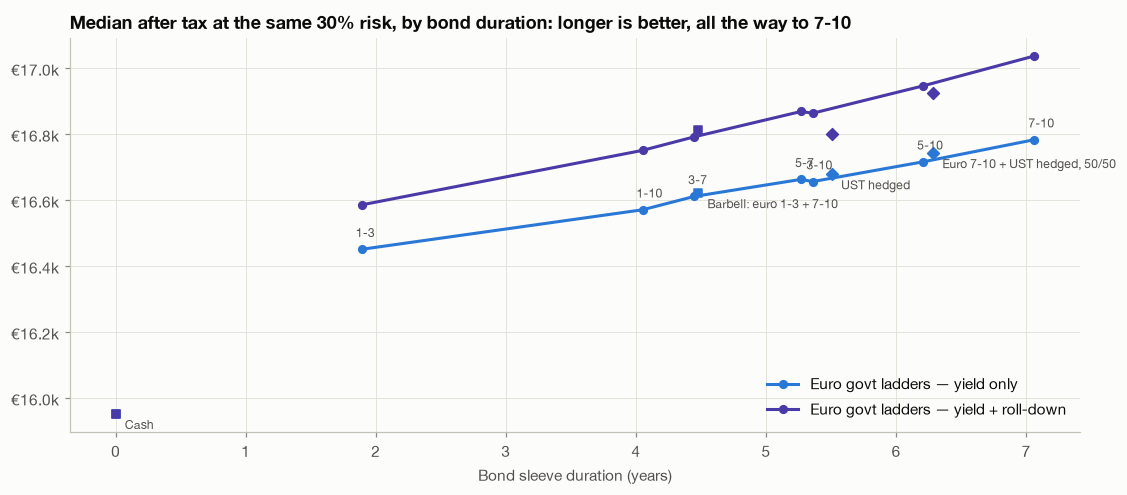

In [32]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
lad_rows = [f"Euro govt {k}" for k in LAD8]
for v, c in [("Yield only", SLOT[0]), ("Yield + roll-down", SLOT[4])]:
    sub = R8.loc[(v, "Mom/Qual/Val 50/25/25")]
    x_ = [BINFO.loc[b, "Duration"] for b in lad_rows]
    ax.plot(x_, sub.loc[lad_rows, "Median €"], "-o", color=c, label=f"Euro govt ladders — {v.lower()}", ms=5)
    for b in ["UST hedged", "Cash (€STR fund)", "Euro 7-10 + UST hedged, 50/50", "Barbell: euro 1-3 + 7-10"]:
        d_ = sum(x * BINFO.loc[k, "Duration"] for k, x in BO8[b].items())
        ax.scatter(d_, sub.loc[b, "Median €"], color=c, marker="D" if "UST" in b else "s", s=30, zorder=3)
        if v == "Yield only":
            ax.annotate(b.replace(" (€STR fund)", ""), (d_, sub.loc[b, "Median €"]), textcoords="offset points", xytext=(6, -10), fontsize=8, color=INK2)
for b in lad_rows:
    ax.annotate(b.replace("Euro govt ", ""), (BINFO.loc[b, "Duration"], R8.loc[("Yield only", "Mom/Qual/Val 50/25/25", b), "Median €"]),
                textcoords="offset points", xytext=(-4, 8), fontsize=8, color=INK2)
ax.yaxis.set_major_formatter(eur_k); ax.set_xlabel("Bond sleeve duration (years)")
ax.set_title("Median after tax at the same 30% risk, by bond duration: longer is better, all the way to 7-10")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 8b · The real funds

The rebuilt ladders are idealised. Over the common history of the real funds — which includes 2022 — the
order is the same. Two alternatives that the simulation does not cover, because their real history is too
short or they hold more than government bonds, are added for reference: **euro inflation-linked**
government bonds (iShares IBCI) and the **aggregate** funds (government + corporate, euro and global hedged).

In [33]:
RFUND = {"X710 · euro govt 7-10": "X710.DE", "SXRP · euro govt 3-7": "SXRP.DE", "DBXP · euro govt 1-3": "DBXP.DE",
         "VGEA · euro govt all maturities": "VGEA.DE", "VDTE · UST, EUR hedged": "VDTE.DE",
         "IBCI · euro inflation-linked": "IBCI.DE", "EUNA · euro aggregate": "EUNA.DE", "AGGH · global aggregate, EUR hedged": "AGGH.MI"}
rr = {}
for k, t in RFUND.items():
    try:
        rr[k] = D.etf_returns(t, END)
    except Exception as ex:
        print(f"{k}: no data ({ex})")
RR = pd.DataFrame(rr).loc[:END].dropna()
wld = H_["World"].reindex(RR.index)
fr8 = pd.DataFrame({"CAGR": (1 + RR).prod() ** (12 / len(RR)) - 1, "Volatility": RR.std() * np.sqrt(12),
                    "2022": (1 + RR.loc["2022"]).prod() - 1, "Max drawdown": RR.apply(lambda s: pf.perf_stats(s)["Max drawdown"]),
                    "Correlation with World": RR.corrwith(wld),
                    "In World's worst 10% months": RR[wld <= wld.quantile(0.10)].mean()})
print(f"Real funds, common history {RR.index[0]:%Y-%m} → {RR.index[-1]:%Y-%m} ({len(RR)} months):")
display(fr8.style.format({c: "{:.1%}" for c in fr8 if c != "Correlation with World"} | {"Correlation with World": "{:+.2f}"}))

Real funds, common history 2020-12 → 2026-09 (70 months):


,CAGR,Volatility,2022,Max drawdown,Correlation with World,In World's worst 10% months
X710 · euro govt 7-10,-3.1%,7.1%,-19.9%,-22.3%,+0.57,-2.2%
SXRP · euro govt 3-7,-1.1%,4.2%,-12.1%,-13.8%,+0.50,-1.1%
DBXP · euro govt 1-3,0.5%,1.6%,-4.7%,-5.7%,+0.40,-0.4%
VGEA · euro govt all maturities,-3.0%,6.2%,-18.3%,-21.5%,+0.58,-1.9%
"VDTE · UST, EUR hedged",-3.3%,5.2%,-14.5%,-21.3%,+0.34,-1.1%
IBCI · euro inflation-linked,0.4%,6.5%,-9.3%,-12.2%,+0.66,-2.2%
EUNA · euro aggregate,-1.9%,4.7%,-13.5%,-17.1%,+0.54,-1.5%
"AGGH · global aggregate, EUR hedged",-1.9%,4.7%,-13.4%,-17.2%,+0.53,-1.3%


### 8c · Rate risk inside a savings plan

A saver who adds money every month is not hurt by rising rates in the way a lump-sum holder is: new money and
coupons are reinvested at the higher yields. What hurts is **a rise just before the money is needed**. Below, the
bond sleeve alone (€1,000 + €100 a month, after fee, before tax) is run through fixed paths of the euro curve —
parallel shifts from today's — and its annual return over 10 years compared.

In [34]:
fidx = pd.date_range(END, periods=H + 1, freq="ME")
tt = np.arange(H + 1) / 12
RPATH = {"Curve unchanged": 0 * tt,
         "+2 points at once, now": np.where(tt > 0, 0.02, 0.0),
         "+3 points over 2 years (1970s-style)": 0.03 * np.minimum(tt / 2, 1),
         "−1.5 points over 2 years (recession)": -0.015 * np.minimum(tt / 2, 1),
         "+2 points in year 9, just before cashing out": 0.02 * np.clip(tt - 8.5, 0, 1)}
SHOWL = ["1-3", "3-7", "5-10", "7-10"]
rp, w12 = {}, {}
for nm, sh in RPATH.items():
    cv = {m: pd.Series(y + sh, index=fidx) for m, y in CUR8.items()}
    for k in SHOWL:
        r = pf.ladder_return({m: cv[m] for m in LAD8[k]}, eqw(LAD8[k])).dropna() - FEE8[k] / 12
        v = 1000.0
        for x in r.values:
            v = v * (1 + x) + 100
        rp[(nm, k)] = float(D.irr_annual(np.array([v]), 1000, 100, len(r))[0])
        w12[(nm, k)] = float((1 + r).rolling(12).apply(np.prod).min() - 1)
RP = pd.DataFrame({"Plan return /yr": pd.Series(rp), "Worst 12 months": pd.Series(w12)}).unstack()
RP.columns = pd.MultiIndex.from_tuples([(a, f"Euro govt {b}") for a, b in RP.columns])
display(RP.loc[list(RPATH)].style.format("{:.1%}")
        .background_gradient(cmap="RdYlGn", subset=["Plan return /yr"], vmin=0.015, vmax=0.06)
        .background_gradient(cmap="RdYlGn", subset=["Worst 12 months"], vmin=-0.09, vmax=0.03))
print("Early rises help a saver (more is reinvested at higher yields); a late rise is the one that hurts long bonds.")

Early rises help a saver (more is reinvested at higher yields); a late rise is the one that hurts long bonds.


### 8d · A fund is not a bond: rate risk, coupons and a blend of durations

A bond **fund** never matures. It keeps its duration constant by selling bonds as they shorten and buying new
long ones, so its price moves with rates on the day you sell, whenever that is. A **bond held to maturity** pays
back its face value on a known date whatever rates did in between. For a saver who needs the money in year 10,
that difference is the whole question. §8a cannot see it: it re-centres each sleeve's *return* on a target, so
every path of a bond fund earns its yield on average and rates never move the outcome by more than history's
noise.

So here the **whole euro curve is simulated** (1–10 years), month by month, from today's level: the monthly
moves of 1999–2026, bootstrapped together with equities (crises and the stock–bond correlation carry over),
de-meaned (no assumed trend in rates) and pulled gently back towards today's curve (half-life ≈ 11 years — what
Bund yields did over every 10-year window since 1972). Every instrument is then valued on the *same* curves:

| Option | What it is | Rate risk at the end | Tax |
|---|---|---|---|
| **Fund 7-10, 3-7, 1-3 (acc)** | X710 / SXRP / DBXP, constant duration | Full: the price on the sale date | 12.5% on the gain, at the end |
| **Fund 7-10 (dist)** | Same bonds, coupons paid out and reinvested in the plan | Full | 12.5% on each coupon as paid, then on the gain |
| **Glide path** | New money into 7-10 for years 1–3, 3-7 for years 4–6, 1-3 for years 7–10; nothing sold | Shrinks over time, but the 7-10 money stays in 7-10 | as the funds |
| **Barbell** | Half 7-10, half 1-3 all along | Half | as the funds |
| **Bonds held to maturity** | Every 3 months the saved money buys a euro government bond maturing at month 120 (€1 per order, 0.2% spread) | **None at the end**: the yield is locked at purchase | 12.5% on coupons as paid; nothing at maturity |
| **Cash (€STR fund)** | One-month money | None, but every rate cut cuts the income | 26% (not a government bond) |

All on their own (bond sleeve only, €1,000 + €100 a month), after fee, stamp duty and tax. Held bonds are a
manual plan — Trade Republic sells government bonds from €1 per order but not by savings plan — so this is the
upper bound of what that effort buys.

In [35]:
MATS = [1, 2, 3, 5, 7, 10]
CV = {m: pf.splice(ea_c[m].loc[:END].dropna(), bund_c[m]).loc["1999-01":END] for m in MATS}
Y0 = {m: CUR8[m] for m in MATS}
rW, YC = D.curve_paths(H_["World"], CV, Y0, H, N, seed=41, eq_target=MC_MU["World"])
CON = np.r_[1000.0, np.full(H - 1, 100.0), 0.0]
FD = {k: D.fund_paths(YC, MATS, LAD8[k], FEE8[k]) for k in ["1-3", "3-7", "7-10"]}
short_r = YC[:, :-1, 0] - (Y0[1] - BINFO.loc["Cash (€STR fund)", "Yield after fee"] - 0.0010)   # cash ≈ the 1y yield less today's gap
CASH_R = short_r / 12 - 0.0010 / 12
idx = np.arange(H + 1)
yrs = lambda a, b: CON * ((idx >= 12 * a) & (idx < 12 * b))
OPT = {
    "Fund 7-10 (acc)": [(FD["7-10"][0], CON, .125, None)],
    "Fund 7-10 (dist)": [(FD["7-10"][0], CON, .125, FD["7-10"][1])],
    "Fund 3-7 (acc)": [(FD["3-7"][0], CON, .125, None)],
    "Fund 1-3 (acc)": [(FD["1-3"][0], CON, .125, None)],
    "Barbell 7-10 + 1-3, half each": [(FD["7-10"][0], CON / 2, .125, None), (FD["1-3"][0], CON / 2, .125, None)],
    "Glide path 7-10 → 3-7 → 1-3": [(FD["7-10"][0], yrs(0, 3), .125, None), (FD["3-7"][0], yrs(3, 6), .125, None),
                                    (FD["1-3"][0], yrs(6, 11), .125, None)],
    "Cash (€STR fund)": [(CASH_R, CON, .26, None)],
}
PAID = 1000 + 100 * np.arange(1, H + 1)
BV = {}
for nm, parts in OPT.items():
    out = [D.sleeve_paths(R, c, tx, income=inc) for R, c, tx, inc in parts]
    BV[nm] = (sum(v for v, _ in out), sum(a for _, a in out))
BV["Bonds held to maturity (bought quarterly)"] = D.held_bonds_paths(YC, MATS, CON)

def brow(v, at):
    r = v / PAID
    dd = (r / np.maximum.accumulate(r, axis=1) - 1).min(axis=1)
    w12 = (v[:, 12:] - v[:, :-12] - 1200).min(axis=1)
    return {"Median €": np.median(at), "Median %/yr": np.median(D.irr_annual(at, 1000, 100, H)),
            "Bad case p5 €": np.percentile(at, 5), "Worst 1% €": np.percentile(at, 1),
            "Spread p5–p95 €": np.percentile(at, 95) - np.percentile(at, 5),
            "P(end < paid in)": (at < 12900).mean(), "Bad-case drawdown on the way": -np.percentile(dd, 5),
            "1-in-20 worst 12 months €": np.percentile(w12, 5)}
BT = pd.DataFrame({k: brow(*v) for k, v in BV.items()}).T
y10 = np.percentile(YC[:, -1, MATS.index(10)], [5, 50, 95])
print(f"Simulated curves: the 10-year yield ends year 10 between {y10[0]:.1%} and {y10[2]:.1%} (5th–95th; today {Y0[10]:.1%}).")
print("The bond sleeve alone, €1,000 + €100 a month for 10 years, after fee, stamp duty and tax:")
display(BT.style.format({**EUR0([c for c in BT if "€" in c]), "Median %/yr": "{:.2%}", "P(end < paid in)": "{:.1%}",
                         "Bad-case drawdown on the way": "{:.1%}"})
        .background_gradient(cmap="Greens", subset=["Median €"]).background_gradient(cmap="RdYlGn", subset=["Bad case p5 €"]))

Simulated curves: the 10-year yield ends year 10 between 1.0% and 7.7% (5th–95th; today 4.1%).
The bond sleeve alone, €1,000 + €100 a month for 10 years, after fee, stamp duty and tax:


,Median €,Median %/yr,Bad case p5 €,Worst 1% €,Spread p5–p95 €,P(end < paid in),Bad-case drawdown on the way,1-in-20 worst 12 months €
Fund 7-10 (acc),"€15,911",3.73%,"€13,652","€12,808","€4,501",1.3%,19.6%,"€-1,687"
Fund 7-10 (dist),"€15,823",3.63%,"€13,471","€12,486","€4,534",2.1%,20.1%,"€-1,713"
Fund 3-7 (acc),"€15,427",3.16%,"€13,694","€13,078","€3,773",0.7%,12.2%,€-967
Fund 1-3 (acc),"€15,006",2.66%,"€13,379","€12,920","€3,884",1.0%,6.3%,€-351
"Barbell 7-10 + 1-3, half each","€15,443",3.18%,"€13,863","€13,315","€3,480",0.2%,11.8%,€-955
Glide path 7-10 → 3-7 → 1-3,"€15,664",3.44%,"€14,051","€13,434","€3,368",0.1%,16.6%,"€-1,178"
Cash (€STR fund),"€13,984",1.36%,"€12,465","€12,103","€3,748",13.2%,6.8%,€-273
Bonds held to maturity (bought quarterly),"€15,124",2.80%,"€14,301","€14,038","€2,100",0.0%,13.3%,€-590


**Inside the whole portfolio.** A bond sleeve's own spread is not the investor's risk: what matters is how it
moves *with* the equities. Below, World plus each bond option on the same simulated paths — equity weight held at
52%, the plan's current mix — so the bond choice is the only thing that changes.

In [36]:
EW = 0.52
rows = {}
for nm in ["Fund 7-10 (acc)", "Fund 7-10 (dist)", "Fund 3-7 (acc)", "Barbell 7-10 + 1-3, half each",
           "Glide path 7-10 → 3-7 → 1-3", "Bonds held to maturity (bought quarterly)", "Cash (€STR fund)"]:
    ev, ea_ = D.sleeve_paths(rW, CON * EW, .26)
    if nm.startswith("Bonds held"):
        bv, ba = D.held_bonds_paths(YC, MATS, CON * (1 - EW))
    else:
        out = [D.sleeve_paths(R, c * (1 - EW), tx, income=inc) for R, c, tx, inc in OPT[nm]]
        bv, ba = sum(v for v, _ in out), sum(a for _, a in out)
    v, at = ev + bv, ea_ + ba
    r = v / PAID
    dd = (r / np.maximum.accumulate(r, axis=1) - 1).min(axis=1)
    rows[nm] = {"Median €": np.median(at), "Bad case p5 €": np.percentile(at, 5), "Worst 1% €": np.percentile(at, 1),
                "P(end < paid in)": (at < 12900).mean(), "Bad-case drawdown": -np.percentile(dd, 5)}
PT = pd.DataFrame(rows).T
PT["vs fund 7-10, median €"] = PT["Median €"] - PT.loc["Fund 7-10 (acc)", "Median €"]
PT["vs fund 7-10, bad case €"] = PT["Bad case p5 €"] - PT.loc["Fund 7-10 (acc)", "Bad case p5 €"]
print(f"World {EW:.0%} + each bond option, same simulated paths (World at its Monte Carlo centre, {MC_MU['World']:.1%}):")
display(PT.style.format({**EUR0(["Median €", "Bad case p5 €", "Worst 1% €"]), "P(end < paid in)": "{:.1%}",
                         "Bad-case drawdown": "{:.1%}", **{c: "{:+,.0f} €" for c in PT if c.startswith("vs")}}))

World 52% + each bond option, same simulated paths (World at its Monte Carlo centre, 6.4%):


,Median €,Bad case p5 €,Worst 1% €,P(end < paid in),Bad-case drawdown,"vs fund 7-10, median €","vs fund 7-10, bad case €"
Fund 7-10 (acc),"€16,699","€13,034","€11,814",4.3%,29.7%,+0 €,+0 €
Fund 7-10 (dist),"€16,642","€12,980","€11,773",4.5%,30.2%,-57 €,-54 €
Fund 3-7 (acc),"€16,510","€12,763","€11,543",5.8%,29.7%,-189 €,-270 €
"Barbell 7-10 + 1-3, half each","€16,540","€12,739","€11,531",6.1%,30.1%,-159 €,-294 €
Glide path 7-10 → 3-7 → 1-3,"€16,601","€12,867","€11,688",5.1%,29.8%,-98 €,-167 €
Bonds held to maturity (bought quarterly),"€16,394","€12,426","€11,171",7.6%,31.3%,-305 €,-608 €
Cash (€STR fund),"€15,895","€11,686","€10,349",11.7%,33.7%,-804 €,"-1,348 €"


### 8e · The bond verdict

- **Euro government 7-10 stays the best bond sleeve at this risk level.** At matched risk the median rises
  with duration, all the way to 7-10: on today's steep euro curve each extra year of duration earns more yield
  and roll-down, and costs little in risk at the portfolio level, where the 30% bad case is set by the
  equities. There is no sweet spot in the middle: **5-10** comes closest (≈ €65 behind at the median, ahead on
  41% of paths), then 5-7 and 3-10 (≈ €120–130), the 1-3 + 7-10 barbell and 3-7 (≈ €160–170 — the barbell is
  just a 3-7 at the same duration), 1-10 (≈ €215), 1-3 (≈ €330) and cash (≈ €830). Counting roll-down widens
  every gap; pairing with World instead of 50/25/25 leaves the ranking essentially unchanged.
- **A fund, not a bond: the rate risk is real, and it lands on the way, not at the end (§8d).** A 7-10 fund
  never matures, so its value moves with rates on the day you sell: on the simulated curves it falls about
  20% at some point in one path in twenty, and loses €1,700 in its worst year. But a *saving* plan's end value
  is far less exposed than that suggests — when rates rise, every new €100 and every coupon buys at the higher
  yield — so its bad-case end value (€13,652 for the sleeve alone) is no worse than the 3-7 or 1-3 funds', and
  its median is €480–900 higher.
- **Holding bonds to maturity removes the end-date risk, at a price.** Buying a bond that matures in year 10
  every quarter gives the narrowest outcomes of anything here (bad case €14,301, worst 1% €14,038, never below
  what was paid in) — but €790 less at the median, because the later bonds are short and earn the low end of
  the curve. Inside the portfolio the trade reverses: its value rises least when equities crash, so World +
  held bonds has a *worse* bad case (−€608) than World + the 7-10 fund. And it is manual: Trade Republic sells
  government bonds from €1 an order, but not by savings plan.
- **Distributing costs about €90 and gains nothing.** The coupons are taxed at 12.5% every year instead of once
  at the end, so less compounds; the price risk is identical. Prefer accumulating funds.
- **A blend of durations buys a better bad case for the bond sleeve, not for the portfolio.** The glide path
  (7-10 for years 1–3, 3-7 for 4–6, 1-3 after; nothing sold) and the half-and-half barbell lift the sleeve's bad
  case by €210–400 and halve its swings. Inside the portfolio both give up median (−€100 to −€160) *and* bad
  case (−€170 to −€290): long bonds rise most when equities fall, and that is what a 30% bad case needs.
- **The price of duration is a 2022-style rate shock**, and it is modest at the portfolio level: about one point
  of portfolio loss per year of bond duration given up (2022: −16% with 7-10, −15% with 5-10, −13% with 3-7,
  −10% with 1-3). In the GFC and COVID the choice barely matters.
- **"One curve, one central bank" is a real concentration, and hedged Treasuries are the fix — at a price.**
  They were the better crash cushion (GFC +17% against +10%, COVID +6% against −3%, correlation with equities
  ≈ −0.3 against ≈ 0), but hedging dollars into euros now costs the ≈ 1.5-point gap in short rates (€STR −
  SOFR), which removes their extra yield. Alone they trail by ≈ €105 at the median; **50/50 with euro 7-10**
  trails by ≈ €40 and is ahead on half the paths — the most of any alternative, because it does best in exactly
  the paths where 7-10 does worst — and is the choice if a second central bank matters to you. Within the euro
  fund, issuer risk is spread across France, Italy, Germany, Spain and the smaller states.
- **Rate risk inside a monthly plan is mostly a late-plan risk.** Rising rates early on *raise* the plan's
  return (new money is reinvested higher), and in a recession longer bonds win. The case that really hurts
  7-10 is a rise just before cashing out (worst 12 months ≈ −8%, plan return ≈ 2.4%/yr against 3.2% for 1-3).
- **Aggregate funds** (government + corporate) lost less than X710 since 2020 (2022: −13% against −20%), but
  only because they are shorter — they behaved like the 3-7 fund, with no better cushion in equity sell-offs —
  and their corporate share is taxed at 26%, not 12.5%. A shorter euro government fund does the same job at the
  lower tax rate. **Euro inflation-linked bonds** (IBCI) lost half as much as X710 in 2022 and are the hedge if
  inflation, not rates, is the worry; but they were the *most* correlated with equities (+0.66) and gave no
  cushion in sell-offs, and their history is too short to simulate here.

**The rule**

| If you want… | Bond sleeve | Bond money each month (≈ €48) | Cost vs 7-10, median |
|---|---|---|---|
| The best outcome at your risk level | **Euro govt 7-10, accumulating** | all in X710 | — |
| One point less in a 2022-style shock | Euro govt ≈ 5-10 | two-thirds X710, one-third SXRP (3-7) | ≈ €45–65 |
| A second central bank (better in deflationary crashes) | Euro 7-10 + UST hedged | half X710, half VDTE | ≈ €40–50 |
| A known amount on a known date, whatever rates do | Government bonds held to maturity | a manual quarterly purchase | ≈ €300 (whole portfolio), and a worse bad case |

**Shortening near the end is insurance, not an improvement.** Sending the new bond money to a 1-3 year fund
(Xtrackers DBXP, LU0290356871) from about year 7 — no selling, so no tax — covers the one case where duration
really hurts, a rate rise just before cashing out. §8d prices that insurance: a glide path costs the whole
portfolio about €100 at the median and slightly worsens its bad case, because the 7-10 money already bought
stays long anyway and the shorter new money cushions equity falls less. Do it if you know the date you need
the money and a late rate shock is the risk you mind most; otherwise stay in 7-10.